# D15. 3주차 미니 프로젝트: 우리 팀 도메인 특화 한국어 ASR 만들고 성능 리포트 쓰기

**음성 AI 전문가 과정 (160h) | 3주차 M3 한국어 ASR Fine-tuning | 4시간 | 팀 프로젝트 (2~3명)**

## 프로젝트 목표
**"우리 팀이 정한 현장에서, 원래 Whisper보다 확실히 나은 받아쓰기 모델을 만들고, 그것을 숫자로 증명하는 리포트를 쓴다."**

1. 사용 장면과 요구 사항을 정하고, 그것을 **측정할 지표와 목표값**으로 바꾼다. (프로젝트 카드)
2. 용어 목록과 문장 틀로 **누수 없는 학습 · 시험 데이터**를 만든다. (D11 · D13)
3. 팀원 **목소리로 시험 세트**를 녹음해 합성음 시험의 한계를 보완한다.
4. 원래 모델 · 프롬프트를 **기준선**으로 재고, **LoRA**로 학습한다. (D13)
5. 같은 시험지로 채점하고 **부트스트랩 · 오류 분석**으로 결과를 판정한 뒤, **개선 실험 하나**(용어 사전 후처리)를 더 해 본다. (D14)
6. 숫자 · 그림 · 해석이 들어간 **성능 리포트**를 자동으로 만들고 3분 동안 발표한다.

## 오늘의 실습 흐름
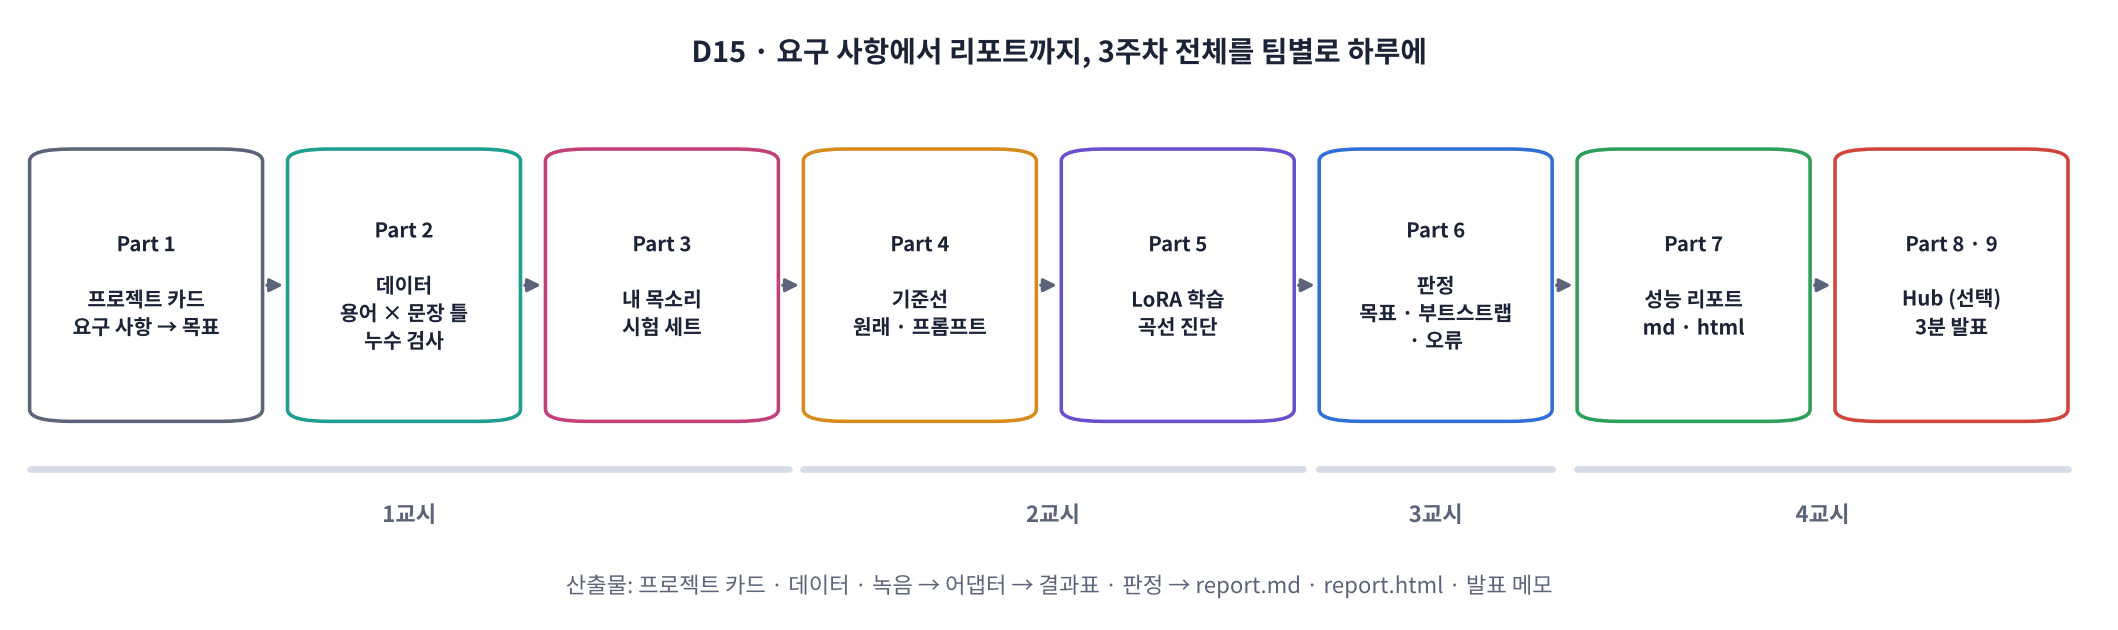

| 교시 | 내용 | 실습 | 산출물 |
|---|---|---|---|
| 1교시 | 팀 · 역할 정하기, 프로젝트 카드, 용어 · 문장 틀, 데이터 만들기, 내 목소리 시험 세트 | Part 0 ~ 3, 워크시트 1교시 | 프로젝트 카드 · 데이터 · 녹음 |
| 2교시 | 기준선(원래 · 프롬프트), LoRA 학습, 학습 곡선 진단 | Part 4 ~ 5, 워크시트 2교시 | 어댑터 (Drive 저장) |
| 3교시 | 같은 시험지로 채점, 목표 판정, 부트스트랩, 오류 분석, 용어 사전 후처리 | Part 6, 워크시트 3교시 | 결과표 · 판정 |
| 4교시 | 성능 리포트 자동 생성, (선택) Hub 업로드, **팀별 3분 발표 · 동료 평가** | Part 7 ~ 9, 워크시트 4교시 | report.md · report.html · 발표 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day15/animation.html) | 각 Part 설명을 볼 때 · 발표 평가표 계산기(D15-9) |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day15/worksheet.html) | 각 교시 끝에 해당 탭 10문항 (4교시 × 10문항), 오답 캡처 → 노션 |

## 이 노트북 사용법
- ▶️ 일반 코드 셀은 위에서부터 차례로 실행합니다. `!`로 시작하는 줄은 리눅스 명령입니다.
- 🧩 **빈칸 실습** 셀은 `____`(밑줄 4개)를 지우고 알맞은 값을 채운 뒤 실행합니다. 마지막 줄에서 ✅ 또는 ❌로 결과를 알려줍니다. 🔑 **정답 및 해설 보기**를 클릭하면 정답이 펼쳐집니다.
- ✏️ **팀이 고칠 곳** 표시가 있는 셀은 팀의 결정(도메인 · 용어 · 목표값 · 리포트 문장)을 적는 곳입니다. 고치지 않아도 기본값으로 끝까지 돌아갑니다.

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 기억할 식 하나 |
| ❓ **생각해 보기** | 스스로 답해 보고 펼쳐서 확인 |
| ✏️ **팀이 고칠 곳** | 팀의 결정을 적는 셀 |

> ⚙️ **T4 GPU** 런타임이 필요합니다(학습 약 5~10분). 팀원 모두 같은 노트북을 돌려도 되지만, **한 명이 학습 · 평가를 맡고** 다른 팀원은 녹음 · 리포트 문장을 준비하면 시간이 넉넉합니다.
>
> 💾 결과(어댑터 · 그림 · 리포트 · 녹음)는 **Google Drive의 `D15_팀이름` 폴더**에 저장됩니다. Colab 세션이 끊겨도 남습니다.

> 🎬 **애니메이션 D15-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day15/animation.html#flow) — Part 1~9 로드맵과 시간 계획

## Part 0. 준비

> 🛠️ **버전 충돌 방지 (D8 ~ D14와 같은 방식)**: Colab 기본 패키지 버전을 고정한 채 필요한 것만 설치합니다. 리포트 그림에 한글이 깨지지 않도록 **나눔 글꼴**도 설치합니다.

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "transformers", "tokenizers", "huggingface-hub",
        "datasets", "accelerate", "click", "numpy", "protobuf", "requests", "markdown"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))

!pip install -q -c colab_constraints.txt peft datasets jiwer soundfile librosa markdown
!pip install -q --no-deps gTTS
!apt-get -qq -y install fonts-nanum > /dev/null
print("✅ 설치 완료")

In [ ]:
import os, io, re, json, time, math, base64, random, hashlib, shutil, subprocess, difflib, datetime
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import torch
import jiwer
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import Audio, display, Markdown
from gtts import gTTS
import importlib.metadata as md

SR = 16000
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

def check(cond, hint="빈칸을 다시 확인하세요."):
    print("✅ 정답입니다! 🎉" if cond else f"❌ {hint}")

# 리포트 그림용 한글 글꼴 (없으면 기본 글꼴)
_ko = [f for f in font_manager.findSystemFonts() if "NanumGothic" in f or "NotoSansCJK" in f]
if _ko:
    font_manager.fontManager.addfont(_ko[0])
    plt.rcParams["font.family"] = font_manager.FontProperties(fname=_ko[0]).get_name()
plt.rcParams["axes.unicode_minus"] = False

GPU = torch.cuda.is_available()
DEVICE = "cuda" if GPU else "cpu"
VERSIONS = {p: md.version(p) for p in ["torch", "transformers", "peft", "datasets", "jiwer", "librosa"]}
VERSIONS["GPU"] = torch.cuda.get_device_name(0) if GPU else "없음 (맛보기 모드)"
print(" · ".join(f"{k} {v}" for k, v in VERSIONS.items()))

def secret(name):                                       # Colab 보안 비밀 → 없으면 환경 변수 → 없으면 None
    try:
        from google.colab import userdata
        v = userdata.get(name)
        if v:
            return v
    except Exception:
        pass
    return os.environ.get(name)
HF_TOKEN = secret("HF_TOKEN")                           # Part 8 (선택)에서만 사용
print("HF_TOKEN:", "✓ 있음" if HF_TOKEN else "— 없음 (Part 8 건너뜀)")

### 0-1. 채점 도구 (D10 · D13 · D14와 같은 기준)
문장 부호 · 띄어쓰기를 지운 뒤 CER, 용어 정확도, 문장별 CER, 부트스트랩을 한곳에 모아 둡니다. 오늘 모든 시스템을 **이 함수들로만** 채점합니다.

In [ ]:
def normalize(s):
    s = re.sub(r"[^\w\s]", "", s.lower())
    return re.sub(r"\s+", "", s)

def cer(rows, preds):
    return 100 * jiwer.cer([normalize(r["text"]) for r in rows], [normalize(p) or "∅" for p in preds])

def term_hits(rows, preds):
    return np.array([normalize(r["term"]) in normalize(p) for r, p in zip(rows, preds)], dtype=float)

def term_acc(rows, preds):
    return 100 * float(term_hits(rows, preds).mean())

def per_sample_cer(rows, preds):
    return np.array([100 * jiwer.cer(normalize(r["text"]), normalize(p) or "∅") for r, p in zip(rows, preds)])

def bootstrap_diff(a, b, n_boot=2000, seed=0):          # D14 빈칸 5 · 6: 짝지은 복원 추출, 95% 구간
    a, b = np.asarray(a, float), np.asarray(b, float); n = len(a)
    rng = np.random.default_rng(seed)
    diffs = [a[idx].mean() - b[idx].mean() for idx in (rng.integers(0, n, n) for _ in range(n_boot))]
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return a.mean() - b.mean(), lo, hi

demo = [dict(text="기록지에 심방세동 항목을 표시해 주세요", term="심방세동")]
print(cer(demo, ["기록지에 심방 세동 항목을 표시해주세요."]), term_acc(demo, ["기록지에 심방 세동 항목을"]))

## Part 1. 프로젝트 카드: 누가, 어디서, 무엇이 좋아져야 하나

> 💬 **쉽게 말하면**: 모델부터 만들지 않습니다. 먼저 **누가 어떤 상황에서 쓰는지**를 정하고, 그 요구 사항을 **숫자로 잴 수 있는 목표**로 바꿉니다. 그래야 마지막에 '성공했다 · 못 했다'를 말할 수 있습니다.

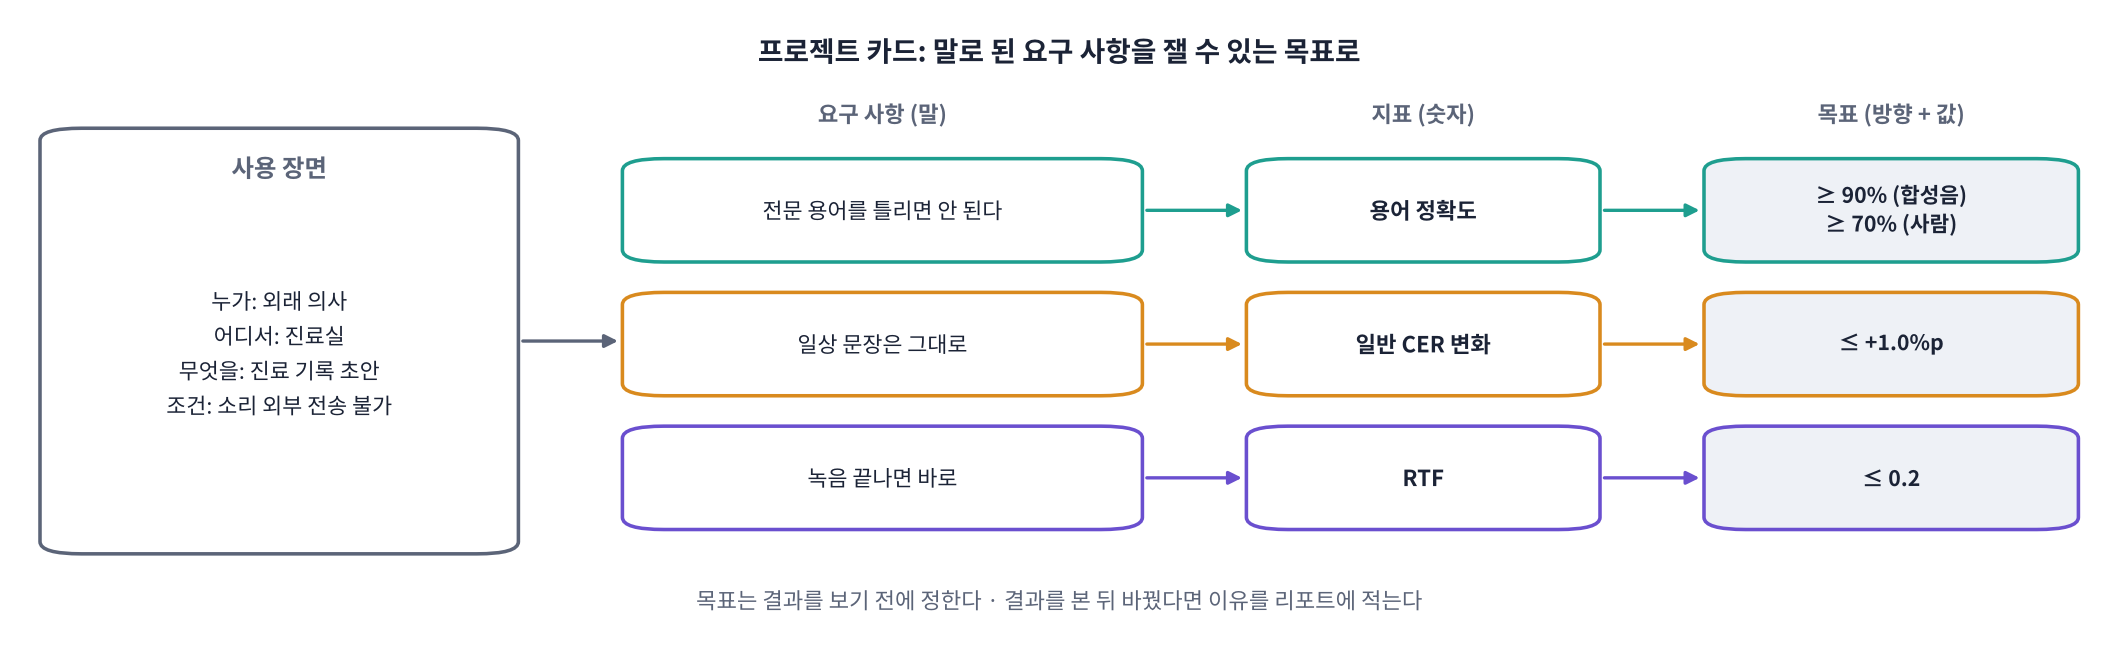

> 🍎 **비유: 맞춤 정장.** 치수(요구 사항)를 재지 않고 옷을 만들면 잘 만들어도 맞는지 알 수 없습니다. "어깨 폭 ±1 cm"처럼 **재는 방법과 허용 범위**를 먼저 정합니다. ASR이라면 "핵심 용어 90% 이상", "일반 문장 실력은 1%p 넘게 나빠지지 않기"처럼요.

| 요구 사항 (말) | 지표 (숫자) | 목표 예 |
|---|---|---|
| 전문 용어를 틀리면 안 된다 | 용어 정확도 | ≥ 90% (합성음), ≥ 70% (사람 목소리) |
| 원래 잘하던 일상 문장은 그대로 | 일반 CER 변화 | ≤ +1.0%p |
| 녹음이 끝나면 바로 결과가 나와야 | RTF | ≤ 0.2 |
| 소리를 밖으로 보낼 수 없다 | 로컬 실행 여부 | 로컬 모델 (API 불가) |

> 🎬 **애니메이션 D15-2:** [요구 사항 → 지표](https://imguru-mooc.github.io/AI_Voice/day15/animation.html#goals) — 사용 장면을 고르면 지표 · 목표값이 어떻게 달라지는지

### ✏️ 팀이 고칠 곳: 프로젝트 카드와 목표
- `domain`: `"의료"` · `"법률"` · `"산업"` 중 하나, 또는 `"직접"`(Part 2에서 용어를 직접 적기)
- `slug`: 저장 폴더 · Hub 저장소 이름에 쓸 **영문 · 숫자 · 하이픈** (예: `team1-medical`)
- `GOALS`: (지표 이름, 방향, 목표값, 이유). 지표 이름은 Part 6 결과표의 열 이름과 같아야 합니다. 쓸 수 있는 이름은 아래 주석을 보세요.

In [ ]:
# ✏️ 팀이 고칠 곳
PROJECT = dict(
    team     = "1조",
    members  = ["김○○ (데이터 · 녹음)", "이○○ (학습)", "박○○ (평가 · 리포트)"],
    domain   = "의료",                                    # "의료" | "법률" | "산업" | "직접"
    slug     = "team1-medical",                           # 영문 · 숫자 · 하이픈
    scenario = "외래 진료 중 의사가 말한 내용을 진료 기록 초안으로 받아쓴다",
    users    = "외래 의사 · 간호사",
    privacy  = "환자 음성은 외부 API로 보낼 수 없음 → 병원 안 GPU에서 도는 로컬 모델",
)
GOALS = [   # (지표, 방향, 목표값, 이유)
    # 쓸 수 있는 지표: "용어(%) · 도메인 TTS", "용어(%) · 내 목소리 도메인",
    #                  "CER(%) · 도메인 TTS", "CER(%) · 내 목소리 일상", "CER 변화(%p) · 일반 Zeroth", "RTF"
    ("용어(%) · 도메인 TTS",        ">=", 90.0, "핵심 용어를 틀리면 기록을 다시 써야 한다"),
    ("용어(%) · 내 목소리 도메인",  ">=", 70.0, "합성음이 아닌 사람 목소리에서도 쓸 만해야 한다"),
    ("CER 변화(%p) · 일반 Zeroth", "<=", 1.0,  "일상 문장 실력이 1%p 넘게 나빠지면 안 된다"),
    ("RTF",                         "<=", 0.2,  "5분 진료 녹음을 1분 안에 받아쓴다"),
]
CFG = dict(
    model_name = "openai/whisper-small" if GPU else "openai/whisper-tiny",
    n_replay   = 200 if GPU else 20,       # 원래 실력 유지용 Zeroth 일반 문장 (학습에 섞기)
    n_general  = 50  if GPU else 10,       # 원래 실력 확인용 Zeroth 시험 문장
    r = 32, alpha = 64,                    # LoRA (D13)
    max_steps  = 200 if GPU else 12,
    batch      = 16 if GPU else 8,
    eval_steps = 50  if GPU else 6,
)
assert re.fullmatch(r"[A-Za-z0-9-]+", PROJECT["slug"]), "slug는 영문 · 숫자 · 하이픈만"

MOUNT_DRIVE = True
DRIVE_ROOT = "."
if MOUNT_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_ROOT = "/content/drive/MyDrive"
    except Exception as e:
        print("Drive 연결 건너뜀 → 현재 폴더에 저장:", type(e).__name__)
OUT_DIR = f"{DRIVE_ROOT}/D15_{PROJECT['slug']}"
os.makedirs(f"{OUT_DIR}/figs", exist_ok=True)
print("저장 폴더:", OUT_DIR)
display(pd.DataFrame(GOALS, columns=["지표", "방향", "목표", "이유"]))

## Part 2. 데이터 설계: 용어 × 문장 틀, 그리고 누수 검사

> 💬 **쉽게 말하면**: D13과 같은 방법입니다. 용어 20~30개를 **문장 틀**에 넣어 문장을 만들고, gTTS로 읽혀 소리를 만듭니다. 이때 **시험에 쓸 문장 틀은 학습에 절대 넣지 않습니다.** 그래야 '문장을 외운 것'이 아니라 '용어를 익힌 것'을 잴 수 있습니다.

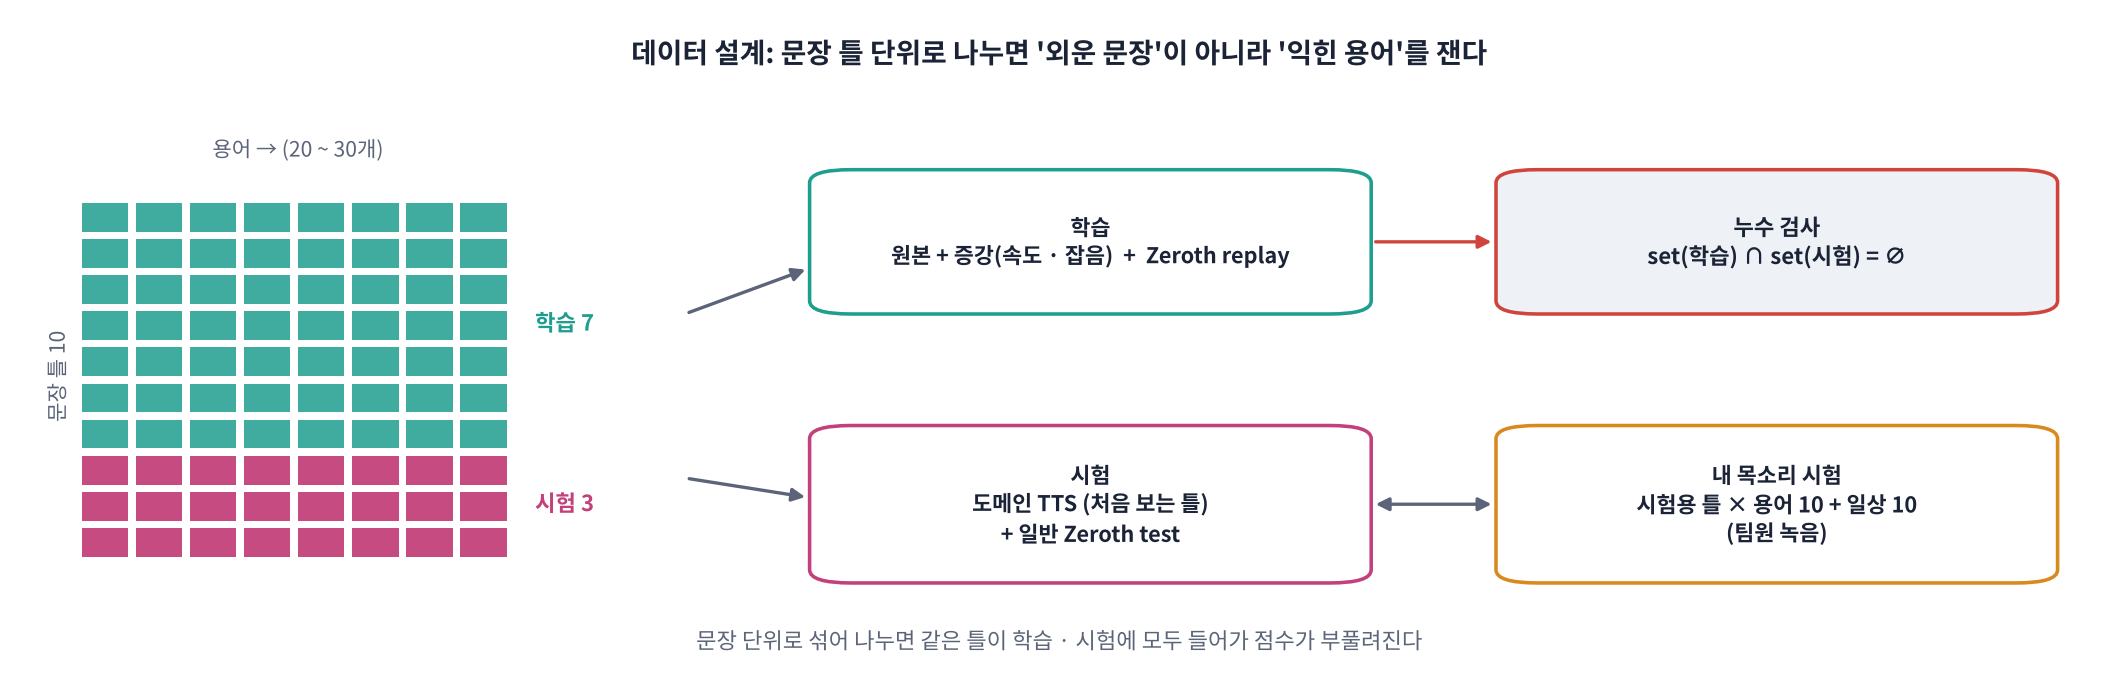

| 설계 결정 | 오늘 기본값 | 바꾸고 싶다면 |
|---|---|---|
| 용어 수 | 20 | 30개까지 권장 (많을수록 데이터 · 학습 시간 ↑) |
| 문장 틀 | 10개 (학습 7 · 시험 3) | 팀 도메인 말투로 고치기 (예: "환자분 {t} 수치가 올라갔습니다") |
| 증강 | 학습 문장마다 1개 (속도 0.9~1.1배 + 약한 잡음) | 그대로 |
| replay | Zeroth 일반 문장 200 | 일반 CER이 나빠지면 늘리기 |

> 📌 **용어 목록 만들기 팁**: ① 현장에서 **자주 쓰고** ② **원래 Whisper가 틀리는** 단어가 좋습니다. 외래어 약품명, 약어, 붙여 쓰는 복합어가 대표적입니다. Part 4 기준선에서 원래 모델이 이미 100% 맞히는 용어는 다른 용어로 바꿔도 됩니다.

> 🎬 **애니메이션 D15-3:** [데이터 설계 · 누수 검사](https://imguru-mooc.github.io/AI_Voice/day15/animation.html#data) — 용어 수 · 문장 틀 · 증강 · replay를 바꿔 데이터 양과 학습 시간 보기

### ✏️ 팀이 고칠 곳: 용어 목록 · 문장 틀
`domain = "직접"`이면 `CUSTOM_TERMS`에 용어를 적으세요. 문장 틀마다 `{t}`가 **한 번** 들어가야 합니다.

In [ ]:
# ✏️ 팀이 고칠 곳
PRESET = {
    "의료": ["심방세동", "트로포닌", "와파린", "메트포르민", "아세트아미노펜", "크레아티닌", "당화혈색소", "심근경색",
             "폐색전증", "패혈증", "기관지확장제", "프레드니솔론", "혈소판감소증", "갑상선기능저하증", "신우신염", "대상포진",
             "담낭절제술", "관상동맥조영술", "항응고제", "인슐린 글라진"],
    "법률": ["소멸시효", "가압류", "근저당권", "손해배상청구", "집행유예", "기판력", "채권자대위권", "부당이득반환",
             "공탁금", "항소이유서", "가처분", "유치권", "사해행위취소", "성년후견인", "상계", "확정판결",
             "소송비용", "공시송달", "이행권고결정", "지급명령"],
    "산업": ["공압 실린더", "서보모터", "인버터 과전류", "PLC 래더", "컨베이어 벨트", "용접 비드", "사출 성형", "금형 온도",
             "진동 센서", "베어링 마모", "유압 펌프", "냉각탑", "안전 인터록", "비상 정지", "토크 렌치", "치공구",
             "공정 능력 지수", "불량률", "설비 종합 효율", "예지 정비"],
}
CUSTOM_TERMS = []                                        # domain = "직접"일 때 20~30개
TEMPLATES = [                                            # 앞 N_TRAIN_TPL개 = 학습, 나머지 = 시험
    "오늘 회의에서 {t} 문제를 다시 다뤘습니다", "{t} 관련 자료를 정리해 주세요", "방금 말씀하신 {t} 부분을 다시 확인하겠습니다",
    "보고서에 {t} 항목을 추가했습니다", "{t} 때문에 일정이 조금 늦어졌습니다", "담당자에게 {t} 내용을 전달했습니다",
    "다음 주까지 {t} 검토를 마치겠습니다",
    "기록지에 {t} 항목을 표시해 주세요", "{t} 경과를 내일 다시 보겠습니다", "고객에게 {t} 설명을 드렸습니다",
]
N_TRAIN_TPL = 7
DAILY = [                                                # 내 목소리 '일상' 시험 문장 (원래 실력 확인용)
    "오늘 아침에 버스를 놓쳐서 조금 늦었습니다", "점심은 회사 근처 식당에서 먹을 예정입니다", "다음 주 화요일로 회의 일정을 다시 잡아 주세요",
    "창문을 조금만 열어 주시겠어요", "주말에는 가족과 함께 공원에 다녀왔습니다", "이 서류를 세 장씩 복사해 주세요",
    "비가 와서 우산을 챙겨 나왔습니다", "엘리베이터가 점검 중이라 계단으로 올라왔어요", "내일까지 보고서를 마무리하겠습니다",
    "전화가 끊겨서 다시 걸어 드렸습니다",
]
TERMS = CUSTOM_TERMS if PROJECT["domain"] == "직접" else PRESET[PROJECT["domain"]]
assert len(TERMS) >= 5, "용어를 5개 이상 적으세요"
assert all(t.count("{t}") == 1 for t in TEMPLATES), "문장 틀마다 {t}가 한 번씩"
assert 1 <= N_TRAIN_TPL < len(TEMPLATES)
PROMPT = ", ".join(TERMS)                                # Part 4 프롬프트 기준선
print(f"도메인 {PROJECT['domain']} · 용어 {len(TERMS)}개 · 문장 틀 {len(TEMPLATES)}개 (학습 {N_TRAIN_TPL} · 시험 {len(TEMPLATES) - N_TRAIN_TPL})")

### 🧩 빈칸 실습 1 · 2: 문장 틀 단위로 나누고 누수 검사
- 빈칸 1: 시험용 문장 틀은 학습용 **바로 다음 번호부터 끝까지**입니다. 학습용 개수를 담은 변수 이름을 넣으세요.
- 빈칸 2: 학습 문장과 **시험 문장**의 교집합이 비어 있어야 누수가 없습니다. 정규화한 뒤 비교하므로 띄어쓰기 · 문장 부호만 다른 문장도 잡아냅니다.

In [ ]:
# 🧩 빈칸 실습 1 · 2
train_tpl = TEMPLATES[:N_TRAIN_TPL]
test_tpl  = TEMPLATES[____:]                                                             # 빈칸 1
train_texts = [tpl.format(t=w) for tpl in train_tpl for w in TERMS]
test_texts  = [tpl.format(t=w) for tpl in test_tpl for w in TERMS]

leak = set(map(normalize, train_texts)) & set(map(normalize, ____))                      # 빈칸 2
LEAK_REPORT = dict(train=len(train_texts), test=len(test_texts), overlap=len(leak))
print(f"학습 문장 {len(train_texts)}개 · 시험 문장 {len(test_texts)}개 · 겹치는 문장 {len(leak)}개")
print("시험 문장 예:", test_texts[:2])
check(len(test_tpl) == len(TEMPLATES) - N_TRAIN_TPL and set(test_tpl).isdisjoint(train_tpl) and len(leak) == 0
      and len(test_texts) == len(test_tpl) * len(TERMS), hint="빈칸 1 = N_TRAIN_TPL, 빈칸 2 = test_texts")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
test_tpl  = TEMPLATES[N_TRAIN_TPL:]
leak = set(map(normalize, train_texts)) & set(map(normalize, test_texts))
```

**해설**: **문장 단위**가 아니라 **문장 틀 단위**로 나누는 것이 핵심입니다. 문장 단위로 섞어 나누면 '기록지에 와파린 …'은 학습에, '기록지에 심방세동 …'은 시험에 들어가 **같은 틀을 외운 효과**로 점수가 부풀려집니다. 누수 검사는 리포트 3장에 그대로 들어갑니다(`LEAK_REPORT`). 팀이 문장 틀을 고쳤다면 비슷한 문장이 학습 · 시험에 동시에 들어가지 않았는지 한 번 더 눈으로 확인하세요. 정규화 후 비교는 '정확히 같은' 문장만 잡습니다.

</details>

In [ ]:
os.makedirs("tts_cache", exist_ok=True)

def tts(text, tries=3):                                 # 같은 문장은 한 번만 합성 (캐시)
    path = f"tts_cache/{hashlib.md5(text.encode()).hexdigest()}.mp3"
    for k in range(tries):
        try:
            if not os.path.exists(path):
                gTTS(text, lang="ko").save(path)
            break
        except Exception as e:                          # 너무 빨리 많이 부르면 잠깐 막힐 수 있음
            print("gTTS 재시도:", e); time.sleep(3 * (k + 1))
    y, _ = librosa.load(path, sr=SR, mono=True)
    return librosa.effects.trim(y, top_db=35)[0].astype(np.float32)

def augment(y, rng):                                    # 속도 0.9~1.1배 + SNR 약 20 dB 잡음
    y2 = librosa.effects.time_stretch(y, rate=rng.uniform(0.9, 1.1))
    noise = rng.normal(0, 1, len(y2)) * np.sqrt(np.mean(y2 ** 2)) / 10
    return (y2 + noise).astype(np.float32)

rng = np.random.default_rng(SEED)
t0 = time.time()
dom_train, dom_test = [], []
for tpl in TEMPLATES:
    for term in TERMS:
        text = tpl.format(t=term); y = tts(text)
        row = dict(audio=y, text=text, term=term)
        if tpl in train_tpl:
            dom_train += [row, dict(row, audio=augment(y, rng))]
        else:
            dom_test.append(row)
print(f"도메인 학습 {len(dom_train)}개 (원본 + 증강) · 도메인 시험 {len(dom_test)}개 · {time.time() - t0:.0f}초")
display(Audio(dom_test[0]["audio"], rate=SR)); print("시험 예:", dom_test[0]["text"])

In [ ]:
from datasets import load_dataset, Audio as HFAudio, Dataset

def read_audio(ex):
    y, sr = sf.read(io.BytesIO(ex["audio"]["bytes"]), dtype="float32")
    if y.ndim > 1:
        y = y.mean(axis=1)
    if sr != SR:
        y = librosa.resample(y, orig_sr=sr, target_sr=SR)
    return y.astype(np.float32)

def take(rows_iter, n):
    out = []
    for ex in rows_iter:
        y = read_audio(ex)
        if ex["text"].strip() and len(y) / SR <= 30:
            out.append(dict(audio=y, text=ex["text"].strip(), term=None))
        if len(out) >= n:
            break
    return out

stream = load_dataset("kresnik/zeroth_korean", split="train", streaming=True).cast_column("audio", HFAudio(decode=False))
replay = take(stream, CFG["n_replay"])
zt = load_dataset("kresnik/zeroth_korean", split="test").cast_column("audio", HFAudio(decode=False))
general_test = take(zt.shuffle(seed=SEED), CFG["n_general"])
print(f"replay(학습에 섞기) {len(replay)}개 · 일반 시험 {len(general_test)}개")

## Part 3. 내 목소리 시험 세트

> 💬 **쉽게 말하면**: gTTS 시험은 **한 사람의 합성 목소리**라 점수가 실제보다 좋게 나옵니다(D13 · D14 한계). 팀원 목소리로 **도메인 문장 10개 + 일상 문장 10개**를 녹음해 '진짜 사람 목소리에서도 좋아졌는지'를 확인합니다. 이것이 오늘 리포트에서 가장 설득력 있는 숫자입니다.

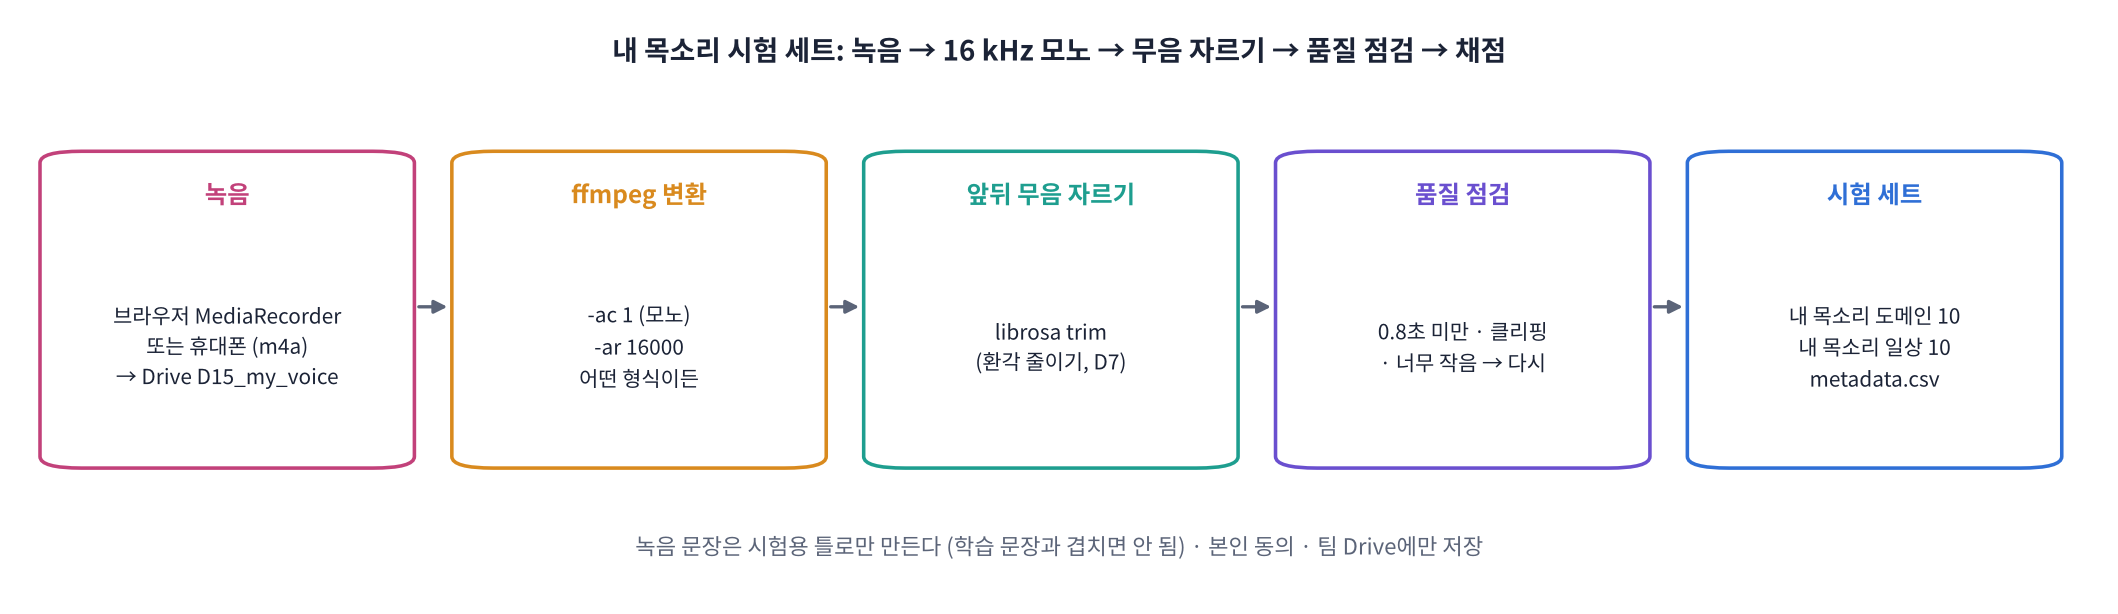

👣 **세 가지 방법 중 하나** (위에서부터 우선)
1. **D14 과제로 녹음해 왔다면**: Drive의 `D15_my_voice/` 폴더에 소리 파일과 `metadata.csv`(`file,text,term,set`)를 넣기
2. **지금 녹음**: 아래 `RECORD_NOW = True`로 바꾸고 실행 → 브라우저 마이크 허용 → 화면에 나오는 문장을 읽기 (문장당 3~8초, 20문장 약 4분)
3. **둘 다 없으면**: 이 단계는 건너뛰고 합성음 · Zeroth 시험만으로 진행 (리포트 '한계'에 적기)

🎙️ **녹음 요령**: 조용한 곳 · 입에서 한 뼘 · 평소 말 속도 · 문장을 끝까지 한 번에. 잘못 읽었으면 그 파일만 지우고 다시 실행하면 이어서 녹음합니다. 팀원 **두 명 이상**이 나눠 읽으면 더 좋습니다.

> 🔒 **녹음 동의**: 녹음은 팀 Drive에만 저장하고, 오늘 평가에만 씁니다. 다른 사람 목소리를 녹음하거나 공개(Hub 업로드)하려면 **본인 동의 범위**를 먼저 확인하세요(D19 · D34).

> 🎬 **애니메이션 D15-4:** [녹음 품질 점검](https://imguru-mooc.github.io/AI_Voice/day15/animation.html#record) — 소리 크기 · 잡음 · 앞뒤 무음을 바꾸며 무엇이 문제인지 찾기

In [ ]:
MY_VOICE_DIR = f"{DRIVE_ROOT}/D15_my_voice"            # 소리 파일 + metadata.csv (file,text,term,set)
RECORD_NOW = False                                         # True: 지금 마이크로 녹음 (Colab 브라우저)
os.makedirs(MY_VOICE_DIR, exist_ok=True)

# 녹음할 문장: 시험용 문장 틀 × 서로 다른 용어 10개 + 일상 10개 (학습 문장은 하나도 없음)
_terms = TERMS[:]; random.Random(SEED).shuffle(_terms)
VOICE_SCRIPT = [(test_tpl[i % len(test_tpl)].format(t=w), w, "내 목소리 도메인") for i, w in enumerate(_terms[:10])]
VOICE_SCRIPT += [(s, "", "내 목소리 일상") for s in DAILY]
assert not set(map(normalize, (t for t, _, _ in VOICE_SCRIPT))) & set(map(normalize, train_texts)), "녹음 문장이 학습 문장과 겹침"
for i, (t, w, s) in enumerate(VOICE_SCRIPT):
    print(f"{i + 1:2d}. [{s.split()[-1]}] {t}")

### 3-1. (선택) 지금 녹음하기
브라우저의 `MediaRecorder`로 녹음해 Drive에 `rec_01.webm` … 으로 저장하고 `metadata.csv`에 한 줄씩 적습니다. 이미 있는 번호는 건너뛰므로 중간에 멈춰도 이어서 녹음할 수 있습니다.

In [ ]:
RECORD_JS = '''
window.recordOne = async function(text, sec) {
  const box = document.createElement('div');
  box.style.cssText = 'font:18px sans-serif;padding:12px 14px;border:2px solid #1E9E8F;border-radius:10px;margin:6px 0';
  document.body.appendChild(box);
  box.innerHTML = '🎙️ 준비 … <b>' + text + '</b>';
  const stream = await navigator.mediaDevices.getUserMedia({audio: true});
  await new Promise(r => setTimeout(r, 1000));
  const rec = new MediaRecorder(stream); const chunks = [];
  rec.ondataavailable = e => chunks.push(e.data);
  rec.start(); box.innerHTML = '🔴 녹음 중 (' + sec + '초) <b>' + text + '</b>';
  await new Promise(r => setTimeout(r, sec * 1000));
  rec.stop(); await new Promise(r => rec.onstop = r); stream.getTracks().forEach(t => t.stop());
  box.innerHTML = '✅ ' + text;
  const b = new Uint8Array(await new Blob(chunks).arrayBuffer()); let s = '';
  for (let i = 0; i < b.length; i += 8192) s += String.fromCharCode.apply(null, b.subarray(i, i + 8192));
  return btoa(s);
};
'''
META = f"{MY_VOICE_DIR}/metadata.csv"

def load_meta():
    return pd.read_csv(META).fillna("") if os.path.exists(META) else pd.DataFrame(columns=["file", "text", "term", "set"])

if RECORD_NOW:
    from IPython.display import Javascript
    from google.colab import output
    display(Javascript(RECORD_JS))
    meta = load_meta()
    for i, (text, term, set_name) in enumerate(VOICE_SCRIPT):
        fname = f"rec_{i + 1:02d}.webm"
        if fname in set(meta["file"]) and os.path.exists(f"{MY_VOICE_DIR}/{fname}"):
            continue
        sec = int(min(8, max(3, 1.5 + 0.18 * len(text))))
        b64 = output.eval_js(f"recordOne({json.dumps(text)}, {sec})")
        open(f"{MY_VOICE_DIR}/{fname}", "wb").write(base64.b64decode(b64))
        meta = pd.concat([meta[meta["file"] != fname], pd.DataFrame([dict(file=fname, text=text, term=term, set=set_name)])])
        meta.to_csv(META, index=False)
    print("녹음 완료:", len(meta), "개 →", META)
else:
    print("RECORD_NOW = False → 녹음 건너뜀 (이미 있는 파일:", len(load_meta()), "개)")

### 🧩 빈칸 실습 3: 어떤 형식이든 16 kHz · 모노로
휴대폰 녹음(m4a), 브라우저 녹음(webm/opus), 44.1 kHz 스테레오 WAV … 형식이 제각각입니다. **ffmpeg**로 한 번에 Whisper 입력 형식(모노 · 16 kHz)으로 바꿉니다. `-ac 1`은 채널 1개(모노), `-ar`은 샘플링 레이트입니다. 오늘 쓰는 **샘플링 레이트 변수**를 넣으세요.

In [ ]:
# 🧩 빈칸 실습 3
def load_any(path):
    tmp = "_conv.wav"
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", path, "-ac", "1", "-ar", str(____), tmp], check=True)   # 빈칸 3
    y, sr = sf.read(tmp, dtype="float32")
    return librosa.effects.trim(y, top_db=35)[0], sr

def quality(y):                                         # 간단 점검: 길이 · 최대 크기(클리핑) · 평균 크기
    peak = float(np.abs(y).max()) if len(y) else 0.0
    rms_db = 20 * np.log10(np.sqrt(np.mean(y ** 2)) + 1e-9) if len(y) else -99
    issues = [m for c, m in [(len(y) / SR < 0.8, "너무 짧음"), (peak > 0.99, "클리핑"), (rms_db < -40, "너무 작음")] if c]
    return dict(초=round(len(y) / SR, 1), 최대=round(peak, 2), 평균dB=round(rms_db, 1), 문제=", ".join(issues) or "OK")

# 확인용: 44.1 kHz 스테레오 1.5초 소리를 만들어 변환해 보기
t = np.arange(int(44100 * 1.5)) / 44100
sf.write("_probe.wav", np.stack([0.3 * np.sin(2 * np.pi * 220 * t), 0.3 * np.sin(2 * np.pi * 330 * t)], 1), 44100)
y_probe, sr_probe = load_any("_probe.wav")
print(f"변환 결과: {sr_probe} Hz · 모양 {y_probe.shape} · {len(y_probe) / sr_probe:.2f}초")
check(sr_probe == SR and y_probe.ndim == 1 and abs(len(y_probe) / SR - 1.5) < 0.05, hint="빈칸 3 = SR")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", path, "-ac", "1", "-ar", str(SR), tmp], check=True)
```

**해설**: Whisper의 feature extractor는 **16 kHz 모노**를 기대합니다. 다른 레이트를 그대로 넣으면 오류는 안 나도 소리가 빨라지거나 느려진 것처럼 들어가 결과가 크게 나빠집니다(D2). ffmpeg는 m4a · webm · mp3 등 거의 모든 형식을 읽으므로, 형식별 코드를 따로 쓰지 않아도 됩니다. 변환 뒤 `trim`으로 앞뒤 무음을 잘라 Whisper의 환각(무음에서 엉뚱한 문장)을 줄입니다(D7). `quality()`는 아주 간단한 점검이니 이상한 파일은 **직접 들어 보세요**.

</details>

In [ ]:
meta = load_meta()
my_dom, my_daily, qrows = [], [], []
for _, m in meta.iterrows():
    path = f"{MY_VOICE_DIR}/{m['file']}"
    if not os.path.exists(path):
        continue
    y, _ = load_any(path)
    q = quality(y); qrows.append(dict(file=m["file"], text=m["text"][:24], **q))
    if q["초"] < 0.8 or q["초"] > 30:
        continue
    row = dict(audio=y.astype(np.float32), text=str(m["text"]).strip(), term=(m["term"] or None))
    (my_dom if row["term"] else my_daily).append(row)
if qrows:
    display(pd.DataFrame(qrows))
    display(Audio(my_dom[0]["audio"] if my_dom else my_daily[0]["audio"], rate=SR))
print(f"내 목소리: 도메인 {len(my_dom)}개 · 일상 {len(my_daily)}개" + ("" if qrows else " → 없음 (리포트 '한계'에 적기)"))

---
### 📝 1교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day15/worksheet.html)** — 요구 사항을 지표로 바꾸기, 목표값과 방향, 용어 고르기, 문장 틀 단위 분할, 누수 검사, 증강 · replay, 합성음 시험의 한계, 녹음 형식(16 kHz 모노), 녹음 동의
>
> 10문항을 풀고 **채점하기**를 누르세요. 채점 후에는 답이 잠깁니다. 제출은 4교시까지 모두 마친 뒤 한 번에 합니다.

## Part 4. 기준선: 원래 모델 · 원래 모델 + 프롬프트

> 💬 **쉽게 말하면**: '좋아졌다'를 말하려면 **무엇보다** 좋아졌는지가 있어야 합니다. 학습 전에 ① 원래 Whisper와 ② 학습 없이 용어 목록만 프롬프트로 준 경우를 먼저 잽니다. 프롬프트만으로 목표를 넘으면, LoRA를 학습할 이유를 다시 생각해야 합니다.

| 시험 세트 | 문장 | 무엇을 보나 |
|---|---|---|
| 도메인 TTS | 시험용 틀 × 용어 (합성음) | 용어를 익혔는지 |
| 일반 Zeroth | Zeroth 공식 test | 원래 실력을 지켰는지 |
| 내 목소리 도메인 · 일상 | 팀원 녹음 (있을 때만) | 사람 목소리에서도 그런지 |

> 📐 **핵심 식 하나: 개선 = 기준선 점수 − 우리 점수** (CER은 낮을수록 좋으므로). 목표 판정과 부트스트랩 모두 이 방향으로 계산합니다.

In [ ]:
from transformers import WhisperProcessor, WhisperForConditionalGeneration
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()                         # 같은 경고가 묶음마다 반복되는 것 숨기기

processor = WhisperProcessor.from_pretrained(CFG["model_name"], language="korean", task="transcribe")
model = WhisperForConditionalGeneration.from_pretrained(CFG["model_name"]).to(DEVICE)
model.generation_config.language = "korean"
model.generation_config.task = "transcribe"
model.accepts_loss_kwargs = False                       # D12 ⚠️: accum 때 loss 평균 보장

def transcribe(m, rows, prompt_ids=None, bs=16):
    m.eval(); out = []
    for i in range(0, len(rows), bs):
        feats = processor.feature_extractor([r["audio"] for r in rows[i:i + bs]], sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
        kw = dict(language="korean", task="transcribe", max_new_tokens=128)
        if prompt_ids is not None:
            kw["prompt_ids"] = prompt_ids.to(DEVICE)
        with torch.no_grad():
            ids = m.generate(input_features=feats, **kw)
        out += [t.strip() for t in processor.batch_decode(ids, skip_special_tokens=True)]
    return out

SETS = {"도메인 TTS": dom_test, "일반 Zeroth": general_test, "내 목소리 도메인": my_dom, "내 목소리 일상": my_daily}
SETS = {k: v for k, v in SETS.items() if v}
ALL_SEC = sum(len(r["audio"]) for rows in SETS.values() for r in rows) / SR
PRED, RTF = {}, {}

def run_system(name, m, prompt_ids=None):
    if GPU: torch.cuda.synchronize()
    t0 = time.time()
    PRED[name] = {s: transcribe(m, rows, prompt_ids) for s, rows in SETS.items()}
    if GPU: torch.cuda.synchronize()
    RTF[name] = (time.time() - t0) / ALL_SEC
    print(f"{name}: {time.time() - t0:.0f}초 · RTF {RTF[name]:.3f}")

def scoreboard():
    rows = []
    for name, P in PRED.items():
        r = {"시스템": name}
        for s, data in SETS.items():
            if data[0]["term"]:
                r[f"용어(%) · {s}"] = term_acc(data, P[s])
            r[f"CER(%) · {s}"] = cer(data, P[s])
        r["RTF"] = RTF.get(name, np.nan)
        rows.append(r)
    return pd.DataFrame(rows).set_index("시스템")

BASE = "① 원래"
run_system(BASE, model)
print("시험 세트:", {k: len(v) for k, v in SETS.items()}, f"· 전체 소리 {ALL_SEC / 60:.1f}분")

### 🧩 빈칸 실습 4: 프롬프트 기준선 (D13 복습)
`get_prompt_ids()`에 Part 2에서 만든 **용어 목록 문자열 변수**를 넣으세요.

In [ ]:
# 🧩 빈칸 실습 4
prompt_ids = processor.get_prompt_ids(____, return_tensors="pt")                       # 빈칸 4
print(f"프롬프트 토큰 {len(prompt_ids)}개 (최대 약 224)")
run_system("② 원래 + 프롬프트", model, prompt_ids)
display(scoreboard().round(2))
check(len(prompt_ids) > len(TERMS) and "② 원래 + 프롬프트" in PRED, hint="빈칸 4 = PROMPT")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
prompt_ids = processor.get_prompt_ids(PROMPT, return_tensors="pt")
```

**해설**: 용어가 30개를 넘으면 프롬프트가 224 토큰 한도에 가까워집니다. 이때는 자주 틀리는 용어만 넣거나 LoRA에 맡깁니다. 표에서 ② 의 **일반 CER**도 꼭 보세요. 모든 문장에 같은 프롬프트를 주면 일상 문장에 엉뚱한 용어를 끼워 넣는 부작용이 생길 수 있습니다. 원래 모델이 이미 100% 맞히는 용어가 많다면 Part 2로 돌아가 **더 어려운 용어로 바꾸는 것**도 좋은 프로젝트 결정입니다(리포트에 적기).

</details>

## Part 5. LoRA 학습과 학습 곡선 진단

> 💬 **쉽게 말하면**: D13 레시피 그대로입니다: q_proj · v_proj에 r = 32 LoRA, 학습률 1e-3, 도메인 문장 + Zeroth replay. 학습이 도는 5~10분 동안 **다른 팀원은 리포트 1장(문제 정의)을 씁니다** (Part 7의 `REPORT_TEXT`).

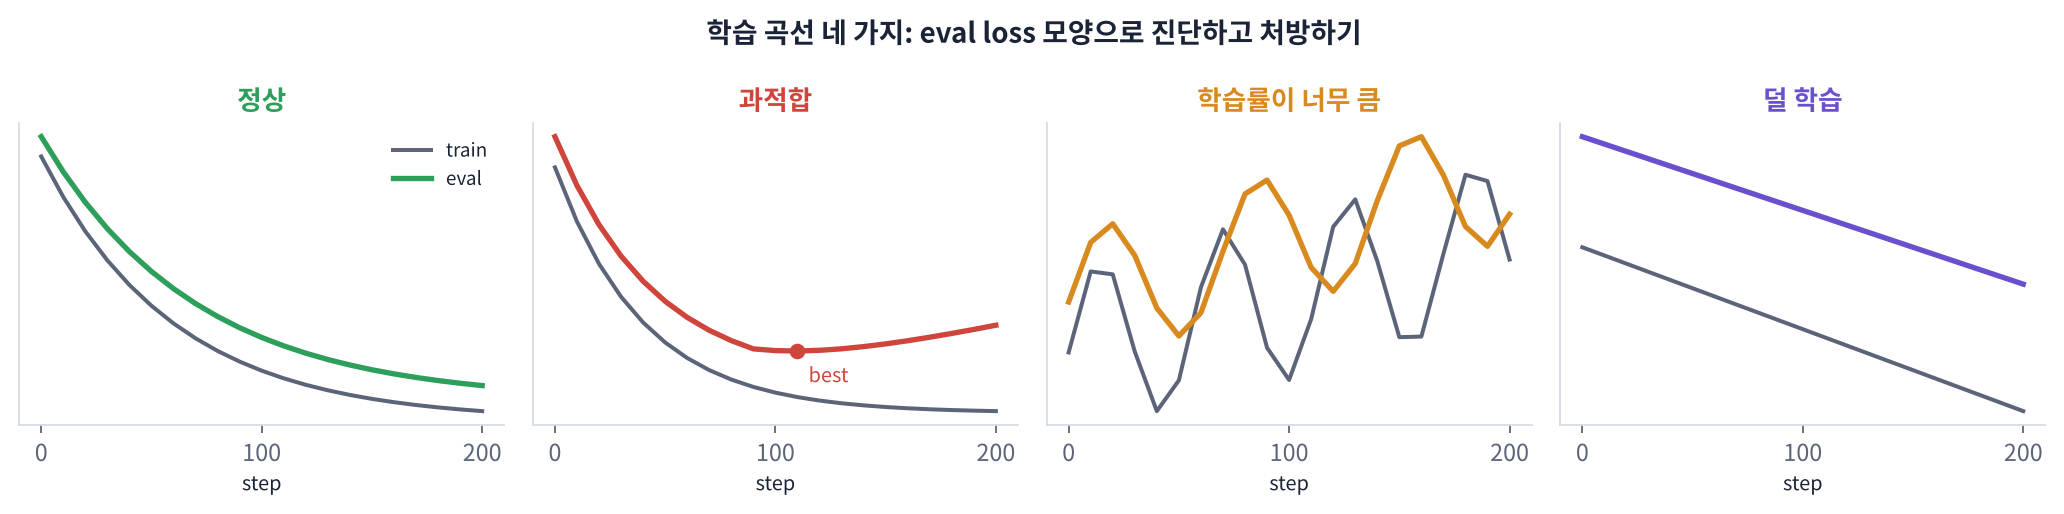

| 곡선 모양 | 진단 | 처방 |
|---|---|---|
| train · eval loss 모두 꾸준히 ↓ | 정상 | 그대로 (step을 늘려 볼 수도) |
| train ↓ 인데 eval이 어느 순간부터 ↑ | 과적합 | best 체크포인트 사용, step ↓, 데이터 · 증강 ↑ |
| 처음부터 출렁이거나 ↑ | 학습률이 너무 큼 | 1e-3 → 5e-4 |
| 거의 안 내려감 | 덜 학습 · 학습률이 너무 작음 | step ↑ 또는 학습률 확인 |

> 🎬 **애니메이션 D15-5:** [학습 곡선 진단](https://imguru-mooc.github.io/AI_Voice/day15/animation.html#curves) — 곡선 네 가지를 보고 진단 · 처방 고르기

### 🧩 빈칸 실습 5 · 6: LoRA 설정 (D13 복습)
- 빈칸 5: query와 함께 LoRA를 붙일 **value 행렬의 모듈 이름**
- 빈칸 6: LoRA 학습률 (Full Fine-tuning 1e-5의 약 100배)

In [ ]:
# 🧩 빈칸 실습 5 · 6
from dataclasses import dataclass
from peft import LoraConfig, get_peft_model
from transformers import Seq2SeqTrainingArguments, Seq2SeqTrainer

lora_cfg = LoraConfig(r=CFG["r"], lora_alpha=CFG["alpha"], lora_dropout=0.05, bias="none",
                      target_modules=["q_proj", ____])                                   # 빈칸 5
model = get_peft_model(model, lora_cfg)
model.print_trainable_parameters()

def prepare_batch(batch):
    feats = processor.feature_extractor(batch["audio"], sampling_rate=SR).input_features
    return {"input_features": feats, "labels": [processor.tokenizer(t).input_ids for t in batch["text"]]}

@dataclass
class DataCollatorSpeechSeq2SeqWithPadding:              # D12 · D13과 같음
    processor: object
    decoder_start_token_id: int
    def __call__(self, features):
        batch = self.processor.feature_extractor.pad([{"input_features": f["input_features"]} for f in features], return_tensors="pt")
        lab = self.processor.tokenizer.pad([{"input_ids": f["labels"]} for f in features], return_tensors="pt")
        labels = lab["input_ids"].masked_fill(lab.attention_mask.ne(1), -100)
        if (labels[:, 0] == self.decoder_start_token_id).all().cpu().item():
            labels = labels[:, 1:]
        batch["labels"] = labels
        return batch

train_rows = dom_train + replay
random.Random(SEED).shuffle(train_rows)
train_ds = Dataset.from_dict({"audio": [r["audio"] for r in train_rows], "text": [r["text"] for r in train_rows]})
eval_ds = Dataset.from_dict({"audio": [r["audio"] for r in dom_test], "text": [r["text"] for r in dom_test]})
train_ds.set_transform(prepare_batch); eval_ds.set_transform(prepare_batch)
collator = DataCollatorSpeechSeq2SeqWithPadding(processor, processor.tokenizer.convert_tokens_to_ids("<|startoftranscript|>"))

def compute_metrics(pred):
    label_ids = pred.label_ids.copy()
    label_ids[label_ids == -100] = processor.tokenizer.pad_token_id
    preds = processor.batch_decode(pred.predictions, skip_special_tokens=True)
    refs = processor.batch_decode(label_ids, skip_special_tokens=True)
    return {"cer": 100 * jiwer.cer([normalize(s) for s in refs], [normalize(p) or "∅" for p in preds]),
            "term_acc": term_acc(dom_test, preds)}

args = Seq2SeqTrainingArguments(
    output_dir=f"lora-{PROJECT['slug']}-ckpt",
    per_device_train_batch_size=CFG["batch"], gradient_accumulation_steps=1,
    learning_rate=____,                                                                  # 빈칸 6
    warmup_steps=max(1, CFG["max_steps"] // 10), max_steps=CFG["max_steps"], fp16=GPU, seed=SEED,
    eval_strategy="steps", eval_steps=CFG["eval_steps"], save_steps=CFG["eval_steps"],
    logging_steps=max(1, CFG["eval_steps"] // 5), per_device_eval_batch_size=16,
    predict_with_generate=True, generation_max_length=128,
    load_best_model_at_end=True, metric_for_best_model="cer", greater_is_better=False, save_total_limit=2,
    remove_unused_columns=False, label_names=["labels"], report_to=[],
)
trainer = Seq2SeqTrainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                         data_collator=collator, compute_metrics=compute_metrics, processing_class=processor)
TRAINABLE = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"학습 {len(train_ds)}개 (도메인 {len(dom_train)} + 일반 {len(replay)}) · lr {args.learning_rate} · step {args.max_steps}")
check(type(model).__name__.startswith("PeftModel") and abs(args.learning_rate - 1e-3) < 1e-12,
      hint='빈칸 5 = "v_proj", 빈칸 6 = 1e-3')

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
target_modules=["q_proj", "v_proj"]
learning_rate=1e-3,
```

**해설**: whisper-small 기준 학습 파라미터 약 354만 개(약 1.4%)입니다(D13). 0에서 시작하는 작은 B 행렬을 키워야 해서 학습률이 Full(1e-5)보다 훨씬 큽니다. `seed=SEED`는 리포트의 **재현 방법**에 그대로 적힙니다. 같은 seed · 같은 버전이면 다른 팀원이 다시 돌려도 거의 같은 결과가 나옵니다(GPU 연산 특성상 아주 작은 차이는 날 수 있음).

</details>

### 5-1. 🚀 학습 실행 (T4 약 5~10분) → 이 동안 리포트 1장 쓰기

In [ ]:
t0 = time.time()
result = trainer.train()
TRAIN_MIN = (time.time() - t0) / 60
print(f"\n학습 끝: {TRAIN_MIN:.1f}분 · step {result.global_step} · best {trainer.state.best_model_checkpoint}")

hist = trainer.state.log_history
tr = pd.DataFrame([h for h in hist if "loss" in h and "eval_loss" not in h])
ev = pd.DataFrame([h for h in hist if "eval_loss" in h])

def diagnose(tr, ev):
    if len(ev) < 2:
        return "평가 기록이 2개 미만이라 판단 보류"
    e = ev["eval_loss"].to_numpy()
    if len(tr) >= 4 and tr["loss"].iloc[-2:].mean() > tr["loss"].iloc[:2].mean():
        return "발산 의심: train loss가 처음보다 커짐 → 학습률이 너무 클 수 있음 (1e-3 → 5e-4)"
    if e[-1] > e.min() * 1.15:
        return "과적합 의심: eval loss가 최저점보다 15% 넘게 올라감 → best 체크포인트 사용 중, step ↓ 또는 데이터 · 증강 ↑"
    if e[-1] > e[0] * 0.95:
        return "덜 학습: eval loss가 거의 안 내려감 → step ↑ 또는 학습률 확인"
    return "정상: eval loss가 꾸준히 내려감"
DIAG = diagnose(tr, ev)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
if len(tr): axs[0].plot(tr["step"], tr["loss"], label="train loss")
if len(ev): axs[0].plot(ev["step"], ev["eval_loss"], "o-", label="eval loss")
axs[0].set_xlabel("step"); axs[0].legend(); axs[0].set_title("loss")
if len(ev):
    axs[1].plot(ev["step"], ev["eval_term_acc"], "o-", color="tab:green", label="용어 정확도(%)")
    axs[1].plot(ev["step"], ev["eval_cer"], "o-", color="tab:purple", label="CER(%)")
axs[1].set_xlabel("step"); axs[1].legend(); axs[1].set_title("도메인 시험 (학습 중)")
plt.tight_layout(); fig.savefig(f"{OUT_DIR}/figs/curves.png", dpi=130); plt.show()
print("진단:", DIAG)

### 5-2. 어댑터 저장 (Drive) · 학습 후 평가

In [ ]:
ADAPTER_DIR = f"{OUT_DIR}/adapter"
model.save_pretrained(ADAPTER_DIR); processor.save_pretrained(ADAPTER_DIR)
ADAPTER_MB = os.path.getsize(f"{ADAPTER_DIR}/adapter_model.safetensors") / 1024**2
print(f"어댑터 저장: {ADAPTER_DIR} ({ADAPTER_MB:.1f} MB)")

run_system("③ LoRA", model)
run_system("④ LoRA + 프롬프트", model, prompt_ids)
display(scoreboard().round(2))

---
### 📝 2교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day15/worksheet.html)** — 기준선을 먼저 재는 이유, 프롬프트 기준선과 부작용, 시험 세트 세 종류, LoRA 설정 복습, seed와 재현성, 학습 곡선 네 가지 진단, best 체크포인트, 어댑터 저장
>
> 10문항을 풀고 **채점하기**를 누르세요.

## Part 6. 판정: 같은 시험지로 채점하고, 목표와 비교하고, 우연이 아닌지 확인

> 💬 **쉽게 말하면**: D14의 방법을 우리 프로젝트에 씁니다. ① 모든 시스템을 같은 함수로 채점 → ② 개선 실험 하나(용어 사전 후처리) → ③ **최종 시스템을 골라 목표와 비교** → ④ 부트스트랩으로 '우연이 아닌지' → ⑤ 남은 오류 읽기.

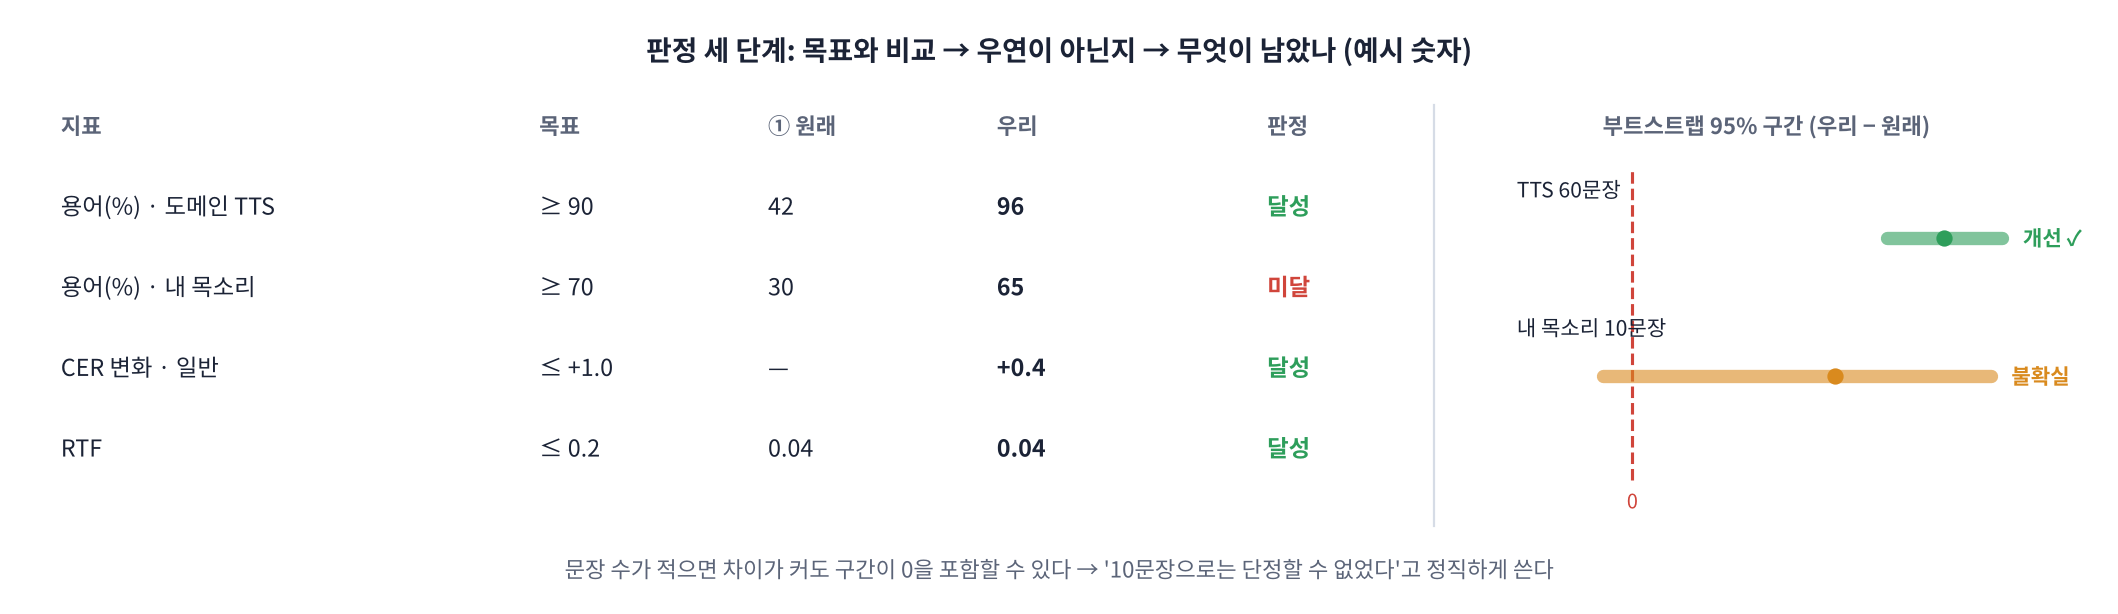

> 🍎 **비유: 건강 검진표.** 수치마다 **정상 범위(목표)** 가 있고, 결과 옆에 '정상 · 주의'가 찍힙니다. 한 번 잰 혈압이 살짝 높다고 바로 병이라 하지 않듯, 시험 문장이 적으면 **신뢰구간**을 함께 봅니다.

> 🎬 **애니메이션 D15-6:** [목표 판정과 신뢰구간](https://imguru-mooc.github.io/AI_Voice/day15/animation.html#ci) — 내 목소리 문장 수를 바꾸며 '개선'이라고 말할 수 있는지 보기

### 6-1. 지금까지의 결과표와 그림

In [ ]:
def plot_results(B, path=None):
    tcols = [c for c in B.columns if c.startswith("용어")]
    ccols = [c for c in B.columns if c.startswith("CER")]
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
    B[tcols].plot.bar(ax=axs[0], rot=0); axs[0].set_title("용어 정확도 (%) · 높을수록 좋음"); axs[0].set_ylim(0, 105)
    B[ccols].plot.bar(ax=axs[1], rot=0); axs[1].set_title("CER (%) · 낮을수록 좋음")
    for a in axs:
        a.set_xlabel(""); a.legend(fontsize=8); a.tick_params(axis="x", labelsize=8)
    plt.tight_layout()
    if path: fig.savefig(path, dpi=130)
    plt.show()

display(scoreboard().round(2))
plot_results(scoreboard())

### 🧩 빈칸 실습 8: 개선 실험, 용어 사전 후처리
학습 없이 **받아쓴 결과를 고치는** 방법입니다. 결과의 단어(1~3개 묶음)마다 용어 목록과 **얼마나 비슷한지** 재서, 충분히 비슷하면 그 용어로 바꿉니다. 예: `트로포인` → `트로포닌`. 비슷한 정도는 `difflib.SequenceMatcher`가 0 ~ 1 사이 값으로 주는데, 그 값을 돌려주는 **메서드 이름**을 넣으세요.

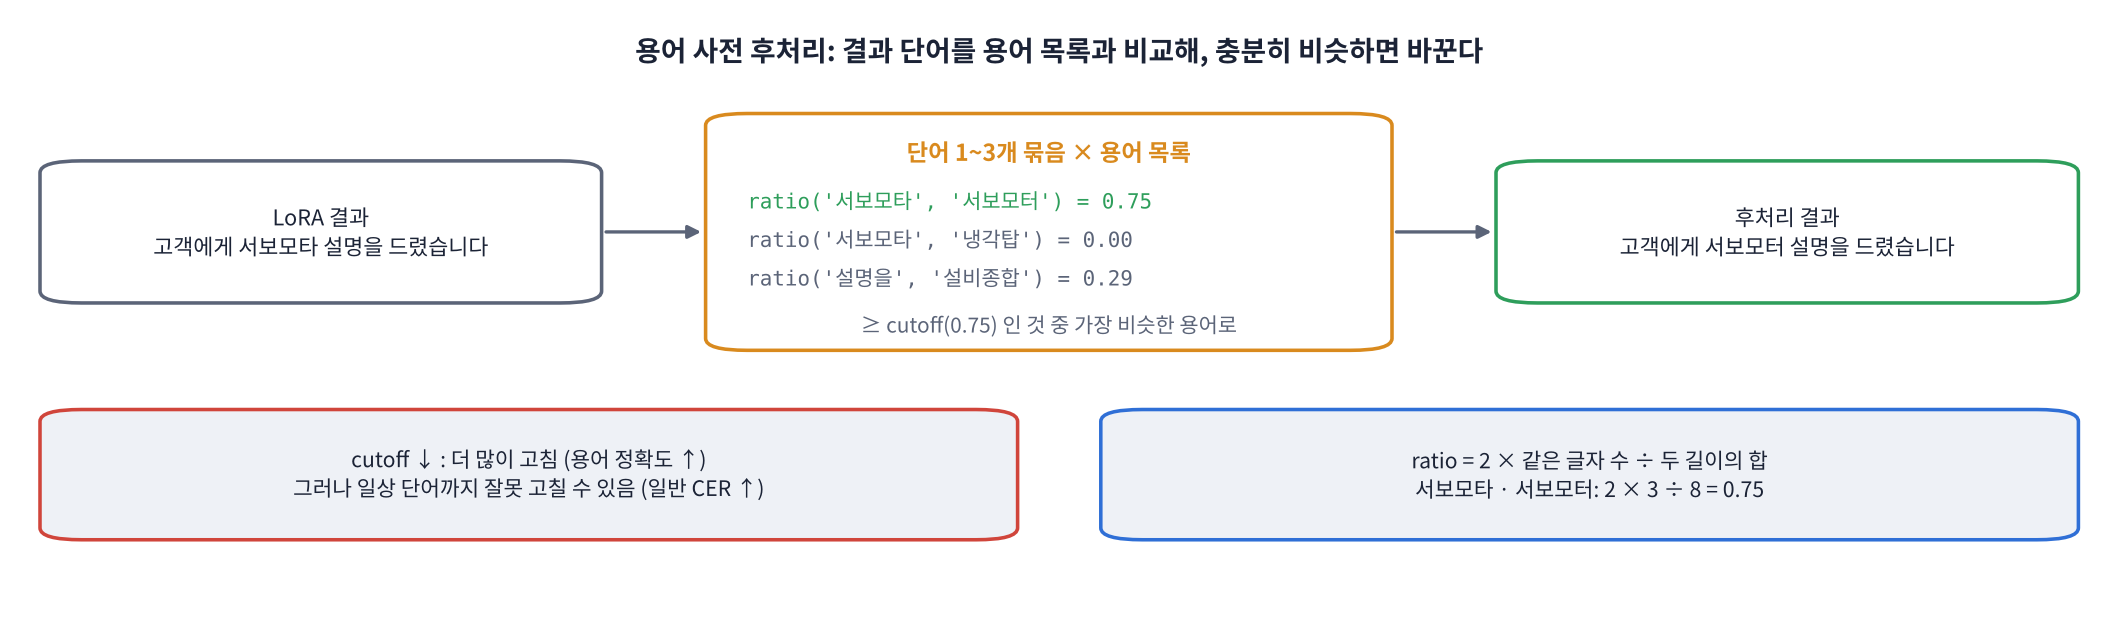

> ⚠️ **부작용 확인이 핵심**: 기준(cutoff)을 낮추면 더 많이 고치지만, 용어가 아닌 일상 단어까지 바꿔 **일반 CER이 나빠질 수** 있습니다. 그래서 일반 · 일상 시험 세트로 꼭 같이 잽니다.

> 🎬 **애니메이션 D15-7:** [용어 사전 후처리](https://imguru-mooc.github.io/AI_Voice/day15/animation.html#fix) — 문장과 기준(cutoff)을 바꿔 무엇이 고쳐지고 무엇이 잘못 고쳐지는지 보기

In [ ]:
# 🧩 빈칸 실습 8
def similarity(a, b):
    return difflib.SequenceMatcher(None, a, b).____()                                    # 빈칸 8

def fix_terms(text, terms=None, cutoff=0.75):
    keys = [(normalize(t), t) for t in (terms or TERMS)]
    words, out, i = text.split(), [], 0
    while i < len(words):
        best = None                                         # (점수, 단어 수, 용어, 뒤에 붙은 말)
        for n in (1, 2, 3):                                 # 용어가 띄어 쓰였을 수 있으므로 1~3단어 묶음
            if i + n > len(words):
                break
            chunk = normalize("".join(words[i:i + n]))
            for key, term in keys:
                score = similarity(chunk[:len(key)], key)   # 앞부분만 비교 (뒤의 조사는 그대로 붙임)
                if score < 1 and len(key) < 3:              # 두 글자 용어는 정확히 같을 때만
                    continue
                if score >= cutoff and (best is None or score > best[0]):
                    best = (score, n, term, chunk[len(key):])
        if best:
            out.append(best[2] + best[3]); i += best[1]
        else:
            out.append(words[i]); i += 1
    return " ".join(out)

demo = fix_terms("고객에게 서보모타 설명을 드렸습니다", ["서보모터", "냉각탑"])
print(demo, "| 비슷한 정도:", round(similarity("서보모타", "서보모터"), 2))
print(fix_terms("기록에 심방 세동이라고 적었습니다", ["심방세동"]))
check(demo == "고객에게 서보모터 설명을 드렸습니다" and abs(similarity("abcd", "abce") - 0.75) < 1e-9, hint="빈칸 8 = ratio")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
return difflib.SequenceMatcher(None, a, b).ratio()
```

**해설**: `ratio()` = 2 × (같은 글자 수) ÷ (두 문자열 길이의 합). '서보모타' vs '서보모터'는 4글자 중 3글자가 같아 2 × 3 ÷ 8 = **0.75**입니다. 용어 길이만큼 앞부분만 비교하고 뒤('이라고' 같은 조사)는 그대로 붙입니다. 띄어 쓴 '심방 세동'은 2단어 묶음으로 잡힙니다. 두 글자 용어('상계')는 비슷한 일상 단어가 너무 많아 **정확히 같을 때만** 고치게 했습니다. 이 방법은 LoRA와 함께 쓸 수 있고, 새 용어를 **학습 없이** 바로 추가할 수 있다는 장점이 있습니다(D13 ❓).

</details>

In [ ]:
CUTOFF = 0.75                                               # ✏️ 팀 실험: 0.65 · 0.75 · 0.85를 바꿔 보며 일반 CER 부작용 확인

def add_post(name, src, fn):
    PRED[name] = {s: [fn(p) for p in PRED[src][s]] for s in SETS}
    RTF[name] = RTF[src]                                    # 후처리 시간은 무시할 만큼 작음

add_post("⑤ LoRA + 용어 사전", "③ LoRA", lambda p: fix_terms(p, cutoff=CUTOFF))
changed = [(a, b) for s in SETS for a, b in zip(PRED["③ LoRA"][s], PRED["⑤ LoRA + 용어 사전"][s]) if a != b]
print(f"후처리로 바뀐 문장 {len(changed)}개")
for a, b in changed[:5]:
    print(f"  {a}\n→ {b}\n")
BOARD = scoreboard()
display(BOARD.round(2))

### 🧩 빈칸 실습 7: 최종 시스템 고르기와 목표 판정
`FINAL = "auto"`면 ③ · ④ · ⑤ 중 **목표를 가장 많이 달성한** 시스템(같으면 도메인 용어 정확도가 높은 것)을 고릅니다. 팀이 직접 이름을 적어도 됩니다.

목표 방향이 `">="`이면 값이 목표 이상일 때, `"<="`이면 **목표 이하**일 때 달성입니다. 알맞은 비교 연산자를 넣으세요.

In [ ]:
# 🧩 빈칸 실습 7
def meets(v, op, target):
    return v >= target if op == ">=" else v ____ target                                  # 빈칸 7

def metric_value(B, name, key):
    if key.startswith("CER 변화(%p) · "):
        col = "CER(%) · " + key.split(" · ", 1)[1]
        return B.loc[name, col] - B.loc[BASE, col] if col in B else np.nan
    return B.loc[name, key] if key in B else np.nan

def goal_table(B, name):
    rows = []
    for key, op, target, why in GOALS:
        v, v0 = metric_value(B, name, key), metric_value(B, BASE, key)
        verdict = "측정 안 함" if pd.isna(v) else ("✅ 달성" if meets(v, op, target) else "❌ 미달")
        rows.append({"지표": key, "목표": f"{'≥' if op == '>=' else '≤'} {target:g}", "① 원래": v0, name: v, "판정": verdict, "이유": why})
    return pd.DataFrame(rows)

FINAL = "auto"                                               # ✏️ 또는 "③ LoRA" · "④ LoRA + 프롬프트" · "⑤ LoRA + 용어 사전"
if FINAL == "auto":
    cands = ["③ LoRA", "④ LoRA + 프롬프트", "⑤ LoRA + 용어 사전"]
    tcol = "용어(%) · 도메인 TTS"
    FINAL = max(cands, key=lambda n: ((goal_table(BOARD, n)["판정"] == "✅ 달성").sum(), BOARD.loc[n, tcol]))
GOAL_TABLE = goal_table(BOARD, FINAL)
N_OK = int((GOAL_TABLE["판정"] == "✅ 달성").sum()); N_MEASURED = int((GOAL_TABLE["판정"] != "측정 안 함").sum())
print(f"최종 시스템: {FINAL} · 목표 {N_OK}/{N_MEASURED} 달성")
display(GOAL_TABLE.round(2))
check(meets(91, ">=", 90) and meets(0.4, "<=", 1.0) and not meets(1.5, "<=", 1.0) and meets(1.0, "<=", 1.0),
      hint="빈칸 7 = <=")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
return v >= target if op == ">=" else v <= target
```

**해설**: 용어 정확도 · 일반 CER 변화 · RTF처럼 **좋아지는 방향이 지표마다 다르기** 때문에 방향을 목표에 함께 적어 둡니다. 경계값(정확히 1.0)은 달성으로 봅니다. '측정 안 함'은 내 목소리 녹음이 없을 때처럼 그 시험 세트가 없는 경우로, 리포트에 그대로 드러나게 했습니다. 목표를 **결과를 본 뒤에 바꾸면 안 됩니다**. 목표를 바꿨다면 그 이유를 리포트에 적으세요.

</details>

### 6-3. 우연이 아닌가: 부트스트랩 (D14)
시험 세트마다 **같은 문장끼리 짝지어** 2,000번 다시 뽑습니다. 차이는 **좋아진 쪽이 양수**가 되게 계산합니다(CER: 원래 − 우리, 용어: 우리 − 원래). 95% 구간 전체가 0보다 크면 '개선'이라고 말할 수 있습니다.

In [ ]:
boot = []
for s, data in SETS.items():
    a = per_sample_cer(data, PRED[BASE][s]); b = per_sample_cer(data, PRED[FINAL][s])
    d, lo, hi = bootstrap_diff(a, b)
    boot.append({"시험 세트": s, "지표": "CER (원래 − 우리, %p)", "n": len(data), "차이": d, "95% 하한": lo, "95% 상한": hi})
    if data[0]["term"]:
        d, lo, hi = bootstrap_diff(100 * term_hits(data, PRED[FINAL][s]), 100 * term_hits(data, PRED[BASE][s]))
        boot.append({"시험 세트": s, "지표": "용어 (우리 − 원래, %p)", "n": len(data), "차이": d, "95% 하한": lo, "95% 상한": hi})
BOOT = pd.DataFrame(boot)
BOOT["판정"] = ["개선 ✓" if lo > 0 else ("악화 ✗" if hi < 0 else "차이 불확실") for lo, hi in zip(BOOT["95% 하한"], BOOT["95% 상한"])]
display(BOOT.round(2))

**결과 읽기**
- **도메인 TTS 용어**: 보통 '개선 ✓'이 뚜렷합니다(문장 60개, 차이가 큼).
- **일반 Zeroth CER**: '차이 불확실'이면 **원래 실력을 지켰다**는 좋은 소식입니다. '악화 ✗'라면 replay를 늘리거나 step을 줄입니다.
- **내 목소리**: 문장이 10개뿐이라 구간이 넓습니다. 차이가 커도 '불확실'이 나올 수 있으니 **"10문장으로는 단정할 수 없었다"** 고 그대로 리포트에 쓰세요. 그것도 정직한 결과입니다.

### 6-4. 남은 오류 읽기: 어떤 용어가 아직 약한가

In [ ]:
def error_type(r, p):                                   # D14와 같은 간단 규칙
    c = jiwer.cer(normalize(r["text"]), normalize(p) or "∅")
    if c == 0:
        return None
    if r["term"] and normalize(r["term"]) not in normalize(p):
        return "용어"
    if re.search(r"\d", r["text"] + p):
        return "숫자 표기"
    return "크게 틀림" if c > 0.5 else "일부 글자"

ERR = pd.DataFrame({name: pd.Series([t for s in SETS for t in (error_type(r, p) for r, p in zip(SETS[s], PRED[name][s])) if t]).value_counts()
                    for name in [BASE, FINAL]}).fillna(0).astype(int)
display(ERR)

term_sets = [s for s in SETS if SETS[s][0]["term"]]
by_term = pd.concat([pd.DataFrame({"용어": [r["term"] for r in SETS[s]],
                                   BASE: term_hits(SETS[s], PRED[BASE][s]), FINAL: term_hits(SETS[s], PRED[FINAL][s])}) for s in term_sets])
WEAK = by_term.groupby("용어").mean().mul(100).round(0).sort_values([FINAL, BASE]).head(5)
print("아직 약한 용어 (우리 시스템 기준 정확도가 낮은 순):"); display(WEAK)

EXAMPLES = [(s, r["text"], p) for s in SETS for r, p in zip(SETS[s], PRED[FINAL][s]) if error_type(r, p)][:4]
for s, t, p in EXAMPLES:
    print(f"[{s}] 정답: {t}\n{' ' * (len(s) + 3)}결과: {p}\n")

**❓ 생각해 보기**: 도메인 TTS 용어 정확도는 95%인데 내 목소리 도메인은 60%라면, 무엇을 의심하고 무엇을 해야 할까요?

<details>
<summary>답 보기</summary>

**합성음에 맞춰진 것(과적합)** 을 의심합니다. 학습 · 시험 소리가 모두 gTTS 한 목소리라, 모델이 '그 목소리의 그 용어'를 배웠을 수 있습니다. 처방: ① 팀원 목소리로 **학습 데이터도** 조금 만들기(시험 문장과 다른 틀로!) ② 다른 TTS 목소리 · 속도 · 잡음 증강 늘리기 ③ 용어 사전 후처리처럼 소리와 무관한 방법 더하기. 그리고 리포트에는 두 숫자를 **나란히** 적어 독자가 오해하지 않게 합니다.

</details>

---
### 📝 3교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day15/worksheet.html)** — 같은 시험지 채점, 후처리 사전과 cutoff, ratio 계산, 부작용 확인, 목표 방향(≥ · ≤), 최종 시스템 선택, 부트스트랩 방향 · 판정, 작은 시험 세트의 넓은 구간, 오류 분석
>
> 10문항을 풀고 **채점하기**를 누르세요.

## Part 7. 성능 리포트 만들기

> 💬 **쉽게 말하면**: 지금까지의 숫자 · 표 · 그림을 모아 **리포트를 자동으로** 만듭니다. 사람이 써야 하는 부분(문제 정의, 해석, 한계, 다음 단계)만 `REPORT_TEXT`에 적으면 됩니다. 결과는 `report.md`(노션 · GitHub에 붙이기)와 `report.html`(그림이 들어간 한 파일)입니다.

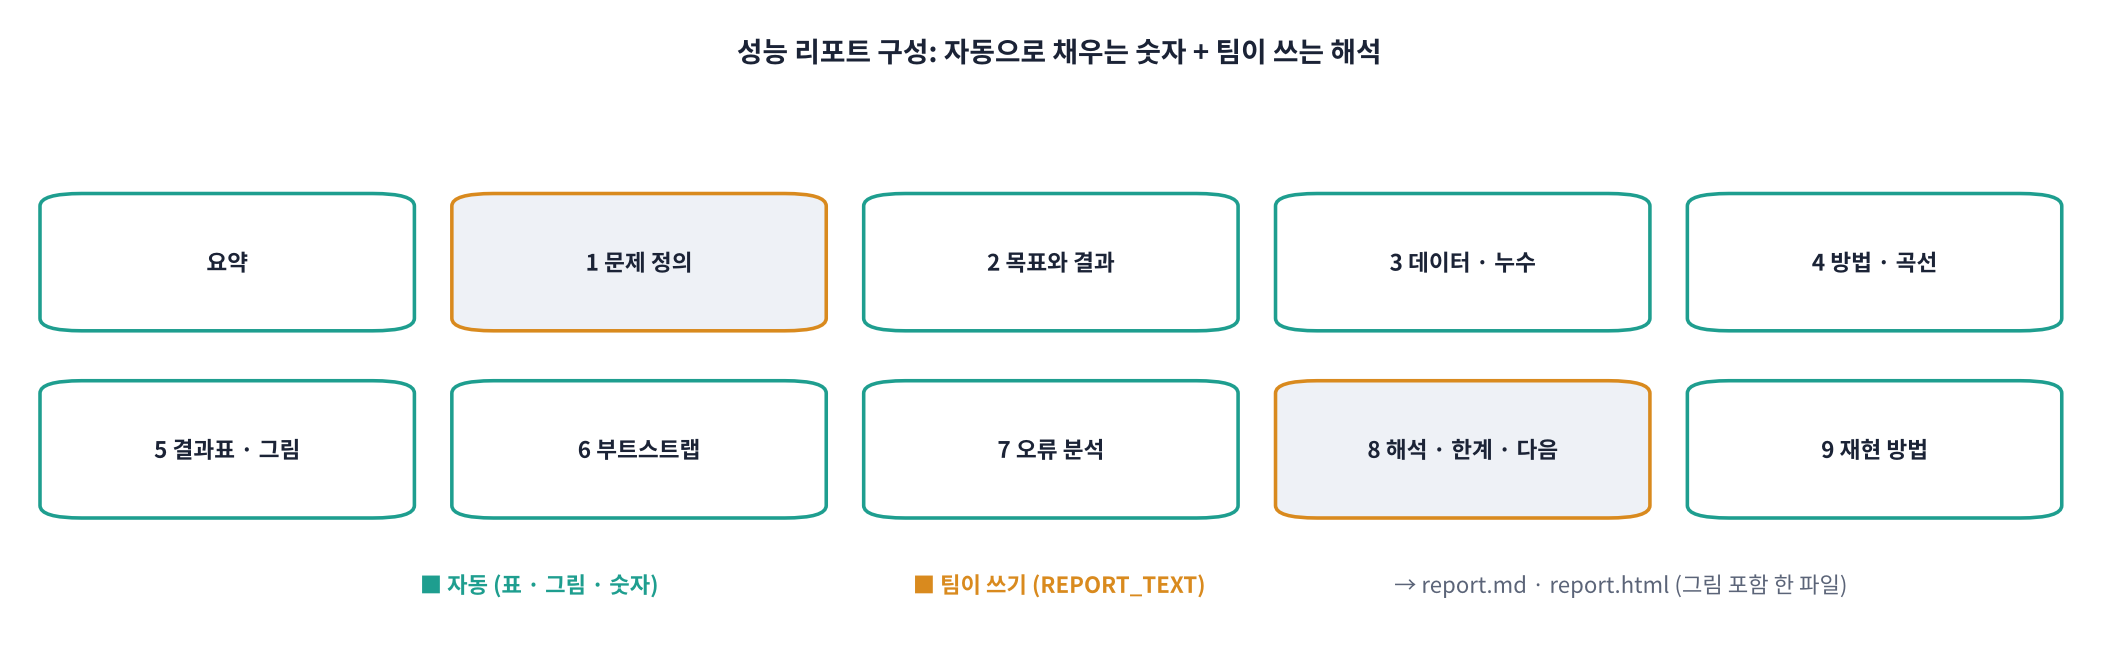

| 장 | 내용 | 누가 |
|---|---|---|
| 요약 | 한 문단 + 요약 카드 그림 | 자동 |
| 1. 문제 정의 | 사용 장면 · 사용자 · 개인정보 조건 · 왜 필요한가 | ✏️ 팀 |
| 2. 목표와 결과 | 목표표 (✅ · ❌) | 자동 |
| 3. 데이터 | 개수 · 용어 · 분할 규칙 · **누수 검사** · 출처 · 라이선스 | 자동 |
| 4. 방법 | 모델 · LoRA 설정 · 학습 시간 · 학습 곡선 · 진단 | 자동 |
| 5 ~ 7. 결과 · 통계 · 오류 | 결과표 · 그림 · 부트스트랩 · 약한 용어 · 예시 | 자동 |
| 8. 해석 · 한계 · 다음 단계 | 가장 중요한 발견, 믿으면 안 되는 부분, 다음에 할 일 | ✏️ 팀 |
| 9. 재현 방법 | 버전 · 설정 · seed · 파일 | 자동 |

> 📌 **좋은 리포트의 세 가지**: ① 숫자 옆에 **어떤 시험 세트**인지 ② 좋은 결과만이 아니라 **나쁜 결과와 한계**도 ③ 다른 사람이 **다시 돌려 볼 수 있는** 정보(재현).

> 🎬 **애니메이션 D15-8:** [리포트 점검](https://imguru-mooc.github.io/AI_Voice/day15/animation.html#report) — 장마다 좋은 예 · 나쁜 예를 비교하고 빠진 것 찾기

### ✏️ 팀이 고칠 곳: 리포트 문장
`TODO`를 지우고 팀의 말로 2~4문장씩 적으세요. **숫자는 위 표에서 그대로** 옮기고, 어떤 시험 세트의 숫자인지 함께 적습니다.

In [ ]:
# ✏️ 팀이 고칠 곳
REPORT_TEXT = dict(
    problem = "TODO: 누가 어떤 상황에서 받아쓰기를 쓰는지, 원래 Whisper로는 무엇이 문제였는지 (기준선 숫자 인용)",
    insight = "TODO: 결과에서 가장 중요한 발견 2~3가지 (예: LoRA로 용어 정확도가 크게 올랐지만 내 목소리에서는 덜 올랐다)",
    limits  = "TODO: 이 결과를 그대로 믿으면 안 되는 부분 (합성음 시험, 적은 녹음 수, 한 사람 목소리 등)",
    next    = "TODO: 다음에 할 일 1~3가지 (데이터 · 모델 · 평가 쪽에서 하나씩)",
)
todo = [k for k, v in REPORT_TEXT.items() if "TODO" in v]
print("아직 TODO인 칸:", todo or "없음 ✓")

In [ ]:
def summary_card(path):
    B = BOARD
    tiles = [("용어 정확도 · 도메인 TTS", f"{B.loc[BASE, '용어(%) · 도메인 TTS']:.0f}% → {B.loc[FINAL, '용어(%) · 도메인 TTS']:.0f}%")]
    if "용어(%) · 내 목소리 도메인" in B:
        tiles.append(("용어 정확도 · 내 목소리", f"{B.loc[BASE, '용어(%) · 내 목소리 도메인']:.0f}% → {B.loc[FINAL, '용어(%) · 내 목소리 도메인']:.0f}%"))
    tiles.append(("일반 CER 변화 (Zeroth)", f"{metric_value(B, FINAL, 'CER 변화(%p) · 일반 Zeroth'):+.1f}%p"))
    tiles.append(("RTF · 어댑터", f"{B.loc[FINAL, 'RTF']:.3f} · {ADAPTER_MB:.1f} MB"))
    fig = plt.figure(figsize=(12, 2.9)); fig.patch.set_facecolor("white")
    fig.text(0.01, 0.92, f"{PROJECT['team']} · {PROJECT['domain']} 특화 ASR · 최종 {FINAL} · 목표 {N_OK}/{N_MEASURED} 달성",
             fontsize=13, fontweight="bold", va="top")
    for i, (k, v) in enumerate(tiles):
        ax = fig.add_axes([0.01 + i * 0.247, 0.06, 0.235, 0.66]); ax.set_xticks([]); ax.set_yticks([])
        ax.set_facecolor("#EEF1F6"); [sp.set_visible(False) for sp in ax.spines.values()]
        ax.text(0.5, 0.68, v, ha="center", va="center", fontsize=19, fontweight="bold", color="#1B2336", transform=ax.transAxes)
        ax.text(0.5, 0.22, k, ha="center", va="center", fontsize=10.5, color="#5B6478", transform=ax.transAxes)
    fig.savefig(path, dpi=130); plt.show()

def md_table(df, digits=2):
    df = df.reset_index() if df.index.name else df
    fmt = lambda x: (f"{x:.{digits}f}" if isinstance(x, (float, np.floating)) and not pd.isna(x) else ("—" if pd.isna(x) else str(x)))
    head = "| " + " | ".join(map(str, df.columns)) + " |\n|" + "---|" * len(df.columns) + "\n"
    return head + "\n".join("| " + " | ".join(fmt(x) for x in row) + " |" for row in df.itertuples(index=False))

plot_results(BOARD, f"{OUT_DIR}/figs/results.png")
summary_card(f"{OUT_DIR}/figs/summary.png")

### 🧩 빈칸 실습 9: 한글 리포트 파일로 저장
리포트에는 한글이 들어 있으므로 파일을 열 때 **문자 인코딩**을 꼭 지정합니다. 운영체제마다 기본값이 달라(예: Windows의 cp949) 지정하지 않으면 깨질 수 있습니다. 표준 인코딩 이름을 문자열로 넣으세요.

In [ ]:
# 🧩 빈칸 실습 9
import markdown as mdlib
B = BOARD
t_base, t_final = B.loc[BASE, "용어(%) · 도메인 TTS"], B.loc[FINAL, "용어(%) · 도메인 TTS"]
voice_line = (f" 팀원 목소리 도메인 문장({len(my_dom)}개)에서는 {B.loc[BASE, '용어(%) · 내 목소리 도메인']:.1f}% → {B.loc[FINAL, '용어(%) · 내 목소리 도메인']:.1f}%였다."
              if "용어(%) · 내 목소리 도메인" in B else " 팀원 목소리 시험 세트는 이번에 만들지 못했다.")
summary = (f"원래 {CFG['model_name']}에 {PROJECT['domain']} 용어 LoRA를 학습했고, 최종 시스템은 **{FINAL}** 이다. "
           f"합성음 도메인 시험({len(dom_test)}문장)에서 용어 정확도가 {t_base:.1f}% → {t_final:.1f}%가 되었고,{voice_line} "
           f"일반 문장(Zeroth {len(general_test)}개) CER 변화는 {metric_value(B, FINAL, 'CER 변화(%p) · 일반 Zeroth'):+.2f}%p이다. 목표 {N_OK}/{N_MEASURED}개를 달성했다.")
IMG = lambda name, alt: f"![{alt}](figs/{name}.png)"         # 리포트 그림 (report.html에서는 base64로 바뀜)
data_tbl = pd.DataFrame([("도메인 학습 (원본 + 증강)", len(dom_train), f"학습용 문장 틀 {len(train_tpl)}개 × 용어 {len(TERMS)}개 × 2"),
                         ("일반 replay (Zeroth train)", len(replay), "원래 실력 유지"),
                         *[(f"시험 · {s}", len(v), "") for s, v in SETS.items()]], columns=["데이터", "개수", "비고"])

REPORT = f'''# {PROJECT["team"]} 성능 리포트: {PROJECT["domain"]} 특화 한국어 ASR

작성: {", ".join(PROJECT["members"])} · {datetime.date.today()} · 음성 AI 전문가 과정 D15 미니 프로젝트

## 요약
{summary}

{IMG("summary", "요약")}

## 1. 문제 정의
- 사용 장면: {PROJECT["scenario"]}
- 사용자: {PROJECT["users"]}
- 개인정보 · 운영 조건: {PROJECT["privacy"]}

{REPORT_TEXT["problem"]}

## 2. 목표와 결과 (최종 시스템: {FINAL})
{md_table(GOAL_TABLE)}

## 3. 데이터
{md_table(data_tbl)}

- 용어 {len(TERMS)}개: {", ".join(TERMS)}
- 분할: **문장 틀 단위** (학습 {len(train_tpl)}개 · 시험 {len(test_tpl)}개). 누수 검사: 학습 {LEAK_REPORT["train"]}문장 vs 시험 {LEAK_REPORT["test"]}문장, 겹침 **{LEAK_REPORT["overlap"]}개**
- 출처: Zeroth-Korean (CC BY 4.0), gTTS 합성음, 팀원 녹음 {len(my_dom) + len(my_daily)}개 (본인 동의, 평가에만 사용)

## 4. 방법
| 항목 | 값 |
|---|---|
| 기반 모델 | {CFG["model_name"]} |
| LoRA | r = {CFG["r"]}, alpha = {CFG["alpha"]}, q_proj · v_proj, 학습 파라미터 {TRAINABLE:,}개 |
| 학습 | lr {args.learning_rate:g}, batch {CFG["batch"]}, {CFG["max_steps"]} step, {TRAIN_MIN:.1f}분, {VERSIONS["GPU"]} |
| 어댑터 크기 | {ADAPTER_MB:.1f} MB |
| 후처리 | 용어 사전, difflib ratio ≥ {CUTOFF} |
| 학습 곡선 진단 | {DIAG} |

{IMG("curves", "학습 곡선")}

## 5. 결과 (모든 시스템, 같은 normalize · CER)
{md_table(BOARD)}

{IMG("results", "결과")}

## 6. 통계적 판정 ({BASE} vs {FINAL}, 부트스트랩 2,000회 · 95% 구간)
{md_table(BOOT)}

## 7. 오류 분석
{md_table(ERR.rename_axis("오류 종류"), 0)}

아직 약한 용어 (정확도 %):

{md_table(WEAK, 0)}

{"".join(f"- [{s}] 정답: {t} → 결과: {p}" + chr(10) for s, t, p in EXAMPLES)}
## 8. 해석 · 한계 · 다음 단계
**해석.** {REPORT_TEXT["insight"]}

**한계.** {REPORT_TEXT["limits"]}

**다음 단계.** {REPORT_TEXT["next"]}

## 9. 재현 방법
- 버전: {", ".join(f"{k} {v}" for k, v in VERSIONS.items())}
- seed: {SEED} · 설정: `{json.dumps(CFG, ensure_ascii=False)}`
- 노트북: D15_미니프로젝트_도메인ASR_실습.ipynb · 어댑터: `{ADAPTER_DIR}`
'''

with open(f"{OUT_DIR}/report.md", "w", encoding=____) as f:                               # 빈칸 9
    f.write(REPORT)

def embed(html):                                        # report.html 한 파일에 그림을 넣기 (base64)
    for name in ["summary", "curves", "results"]:
        b64 = base64.b64encode(open(f"{OUT_DIR}/figs/{name}.png", "rb").read()).decode()
        html = html.replace(f'src="figs/{name}.png"', f'src="data:image/png;base64,{b64}"')
    return html
CSS = "body{font-family:'Noto Sans KR','Malgun Gothic',sans-serif;max-width:980px;margin:24px auto;padding:0 16px;line-height:1.6;color:#1B2336}table{border-collapse:collapse;margin:8px 0;font-size:.92em}td,th{border:1px solid #D6DCE6;padding:4px 8px}th{background:#EEF1F6}img{max-width:100%}h2{border-bottom:2px solid #1E9E8F;padding-bottom:4px}"
html = embed(mdlib.markdown(REPORT, extensions=["tables"]))
with open(f"{OUT_DIR}/report.html", "w", encoding=____) as f:                              # 빈칸 9 (같은 값)
    f.write(f"<!doctype html><html lang='ko'><meta charset='utf-8'><title>{PROJECT['team']} 성능 리포트</title><style>{CSS}</style><body>{html}</body></html>")

back = open(f"{OUT_DIR}/report.md", encoding="utf-8").read()
print(f"report.md {len(back):,}자 · report.html {os.path.getsize(f'{OUT_DIR}/report.html') / 1024:.0f} KB → {OUT_DIR}")
if todo:
    print("⚠️ REPORT_TEXT에 TODO가 남아 있습니다:", todo)
display(Markdown(REPORT.split("## 3.")[0].replace(IMG("summary", "요약"), "")))
check(back == REPORT and "## 9. 재현 방법" in back and "<table>" in html, hint='빈칸 9 = "utf-8"')

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
with open(f"{OUT_DIR}/report.md", "w", encoding="utf-8") as f:
with open(f"{OUT_DIR}/report.html", "w", encoding="utf-8") as f:
```

**해설**: UTF-8은 한글을 포함한 세계 모든 문자를 담는 표준 인코딩입니다. Colab(리눅스)은 기본값이 UTF-8이라 빠뜨려도 동작하는 경우가 많지만, Windows에서 같은 코드를 돌리면 cp949로 저장돼 다른 프로그램에서 깨질 수 있습니다. **읽을 때도 같은 인코딩**으로 엽니다(위 `back`). report.html은 그림을 base64로 품고 있어 **파일 하나만 보내도** 그림까지 보입니다. 노션에는 report.md 내용을 붙여 넣고 그림 3장은 따로 끌어다 놓으세요.

</details>

## Part 8. (선택) Hugging Face Hub에 어댑터 · 리포트 올리기

D14와 같은 방법입니다. `HF_TOKEN`(write)이 있으면 **비공개 저장소**에 어댑터와 모델 카드(리포트 요약), report.md를 올립니다. 없으면 건너뜁니다.

> ⚠️ 팀원 녹음은 올리지 않습니다(어댑터 · 리포트만). 공개로 바꾸기 전에 **데이터 라이선스와 녹음 동의 범위**를 확인하세요.

In [ ]:
REPO_ID = None
if HF_TOKEN:
    from huggingface_hub import HfApi
    api = HfApi(token=HF_TOKEN)
    REPO_ID = f"{api.whoami()['name']}/{CFG['model_name'].split('/')[-1]}-ko-{PROJECT['slug']}-lora"
    api.create_repo(REPO_ID, private=True, exist_ok=True)
    shutil.rmtree("hub_upload", ignore_errors=True); shutil.copytree(ADAPTER_DIR, "hub_upload")
    CARD = f'''---
language: ko
license: apache-2.0
base_model: {CFG["model_name"]}
library_name: peft
pipeline_tag: automatic-speech-recognition
tags: [whisper, korean, lora, {PROJECT["slug"]}]
datasets: [kresnik/zeroth_korean]
metrics: [cer]
---
# {PROJECT["team"]} · {PROJECT["domain"]} 특화 Whisper LoRA

{summary}

{md_table(GOAL_TABLE[["지표", "목표", "① 원래", FINAL, "판정"]])}

## 한계
{REPORT_TEXT["limits"]}

## 사용법
```python
from transformers import WhisperForConditionalGeneration
from peft import PeftModel
base = WhisperForConditionalGeneration.from_pretrained("{CFG["model_name"]}")
model = PeftModel.from_pretrained(base, "{REPO_ID}")
```
자세한 내용: report.md
'''
    open("hub_upload/README.md", "w", encoding="utf-8").write(CARD)
    shutil.copy(f"{OUT_DIR}/report.md", "hub_upload/report.md")
    shutil.copytree(f"{OUT_DIR}/figs", "hub_upload/figs", dirs_exist_ok=True)
    api.upload_folder(folder_path="hub_upload", repo_id=REPO_ID)
    print(f"업로드 완료: https://huggingface.co/{REPO_ID}")
    print("파일:", api.list_repo_files(REPO_ID))
else:
    print("HF_TOKEN 없음 → 건너뜀 (리포트는 Drive에 저장되어 있습니다)")

## Part 9. 발표 · 동료 평가 · 정리

### 3분 발표 구성 (+ 질문 1분)
| 순서 | 시간 | 말할 것 | 보여 줄 것 |
|---|---|---|---|
| 1. 문제 | 30초 | 누가 · 어디서 · 무엇이 문제였나 (기준선 숫자 하나) | 리포트 1장 |
| 2. 데이터 · 방법 | 40초 | 용어 · 문장 틀 · 누수 검사 · LoRA 설정 | 리포트 3 · 4장 |
| 3. 결과 · 판정 | 60초 | 목표표 ✅ · ❌, 부트스트랩 판정, **내 목소리 결과** | 요약 카드 · 목표표 |
| 4. 오류 · 한계 | 30초 | 아직 약한 용어, 믿으면 안 되는 부분 | 리포트 7 · 8장 |
| 5. 다음 단계 | 20초 | 하나만 더 한다면? | — |

아래 셀이 발표 메모를 만들어 줍니다. 그대로 읽기보다 **숫자를 확인하는 용도**로 쓰세요.

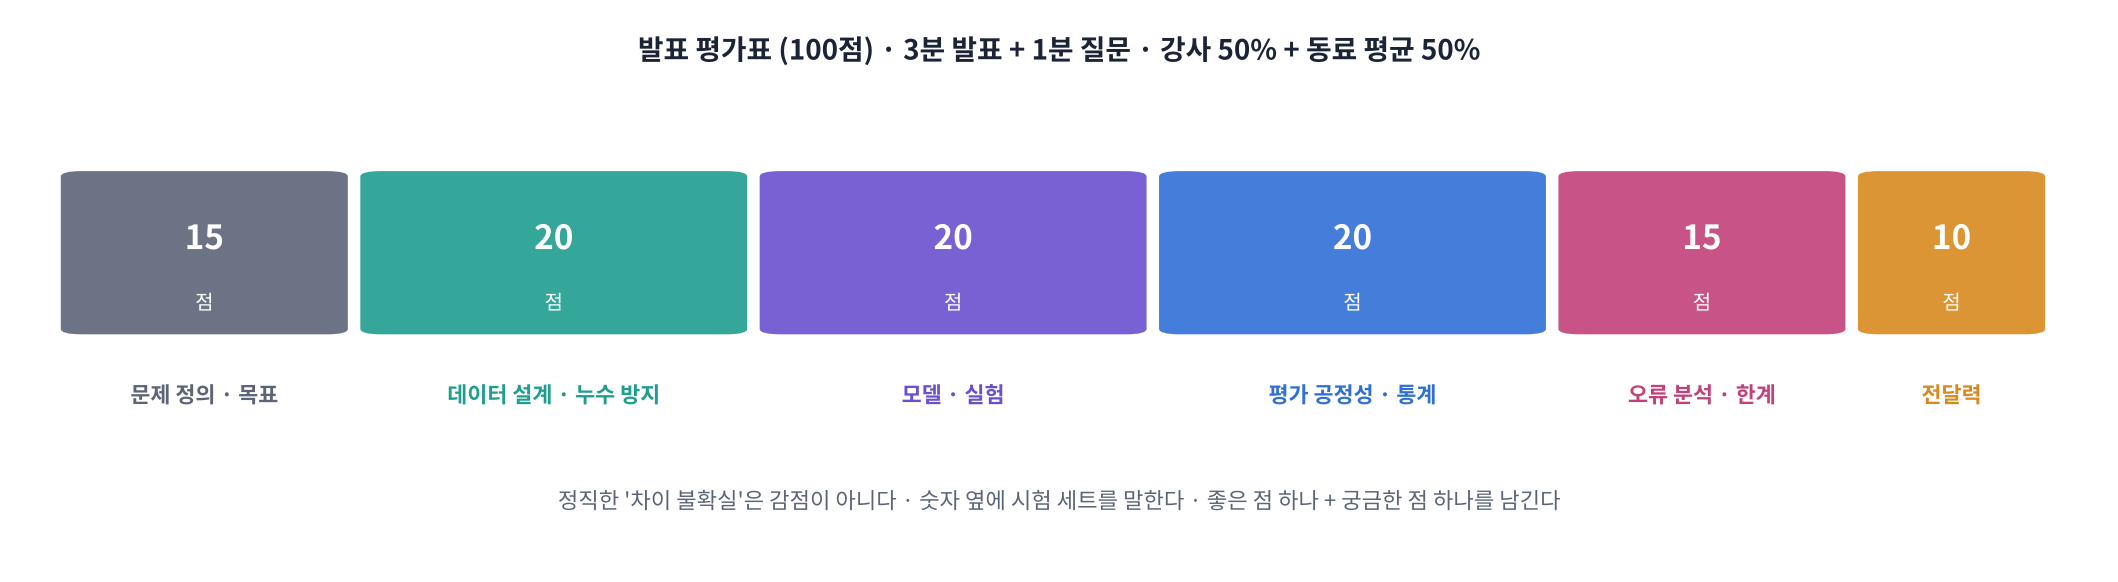

### 발표 평가표 (100점, 강사 50% + 동료 평균 50%)
| 항목 | 배점 | 높은 점수의 모습 |
|---|---|---|
| 문제 정의 · 목표 | 15 | 사용 장면이 구체적이고, 목표가 **숫자 · 방향**으로 정해져 있다 |
| 데이터 설계 · 누수 방지 | 20 | 문장 틀 단위 분할 · 누수 검사 · 내 목소리 시험 세트가 있다 |
| 모델 · 실험 | 20 | 기준선(원래 · 프롬프트) 대비 비교, 개선 실험 1개 이상, 학습 곡선 진단 |
| 평가의 공정성 · 통계 | 20 | 같은 normalize · CER, 부트스트랩 판정을 **정직하게** 해석 |
| 오류 분석 · 한계 | 15 | 약한 용어 · 예시 문장 · 한계를 스스로 말한다 |
| 전달력 | 10 | 3분 안에 핵심 숫자가 들린다, 리포트가 재현 가능하다 |

> 🎬 동료 평가는 [D15-9 발표 평가표 계산기](https://imguru-mooc.github.io/AI_Voice/day15/animation.html#rubric)에서 점수를 매기고 **복사** 버튼으로 노션 평가 페이지에 붙입니다. 좋은 점 하나 · 궁금한 점 하나를 꼭 적습니다.

In [ ]:
BOOT_LINE = "; ".join(f"{r['시험 세트']} {r['지표'].split()[0]} {r['판정']}" for _, r in BOOT.iterrows())
PITCH = f'''🎤 {PROJECT["team"]} 발표 메모
1. 문제: {PROJECT["scenario"]} — 원래 모델 용어 정확도 {BOARD.loc[BASE, "용어(%) · 도메인 TTS"]:.0f}% (합성음 {len(dom_test)}문장)
2. 데이터 · 방법: 용어 {len(TERMS)}개 × 학습용 틀 {len(train_tpl)}개 (+증강, replay {len(replay)}) · 누수 {LEAK_REPORT["overlap"]}개 · LoRA r={CFG["r"]} · {TRAIN_MIN:.0f}분 학습
3. 결과: 최종 {FINAL} · 목표 {N_OK}/{N_MEASURED} 달성 · 용어 {BOARD.loc[FINAL, "용어(%) · 도메인 TTS"]:.0f}% · 일반 CER {metric_value(BOARD, FINAL, "CER 변화(%p) · 일반 Zeroth"):+.1f}%p
   부트스트랩: {BOOT_LINE}
4. 약한 용어: {", ".join(WEAK.index[:3])}
5. 다음 단계: {REPORT_TEXT["next"][:60]}
'''
print(PITCH)
open(f"{OUT_DIR}/pitch.txt", "w", encoding="utf-8").write(PITCH)
print("저장된 파일:", sorted(os.listdir(OUT_DIR)))

---
### 📝 4교시 마무리: 개념 워크시트 · 제출

> **[worksheet.html 열기 → 4교시 탭](https://imguru-mooc.github.io/AI_Voice/day15/worksheet.html)** — 리포트 구성, 숫자와 시험 세트를 함께 쓰기, 한계 쓰기, 재현 정보, UTF-8, 모델 카드 · 비공개 업로드, 녹음 공개 동의, 발표 구성, 동료 평가
>
> 10문항을 풀고 **채점하기**를 누르세요.

### 오늘 한 것 (3주차 전체를 하루에)
| 단계 | 오늘 한 일 | 배운 날 | 코드 |
|---|---|---|---|
| 요구 사항 → 지표 | 프로젝트 카드 · `GOALS` | D14 | `meets()` |
| 데이터 | 용어 × 문장 틀 · 증강 · replay · 누수 검사 | D11 · D13 | `TEMPLATES[N_TRAIN_TPL:]` |
| 내 목소리 | 녹음 · 16 kHz 모노 변환 · 품질 점검 | D2 · D4 | `ffmpeg -ac 1 -ar 16000` |
| 기준선 | 원래 · 프롬프트 | D7 · D13 | `get_prompt_ids(PROMPT)` |
| 학습 | LoRA · 학습 곡선 진단 | D12 · D13 | `LoraConfig`, `diagnose()` |
| 개선 실험 | 용어 사전 후처리 · 부작용 확인 | D10 | `SequenceMatcher.ratio()` |
| 판정 | 목표표 · 부트스트랩 · 오류 분석 | D14 | `goal_table()`, `bootstrap_diff()` |
| 공유 | 리포트 md · html · (Hub) · 발표 | D14 | `encoding="utf-8"` |

### ✅ 제출 (노션)
1. **report.html**(또는 report.md 내용 + 그림 3장)을 팀 페이지에 올립니다.
2. 워크시트 4개 교시를 채점하고 **제출 → 📋 캡처**를 붙입니다(개인별).
3. 다른 팀 동료 평가(D15-9 계산기 결과)를 평가 페이지에 붙입니다.

> 📝 **[D15 개념 워크시트 열기](https://imguru-mooc.github.io/AI_Voice/day15/worksheet.html)** — 4교시 × 10문항 (객관식 5 · OX 2 · 선잇기 1 · 순서 맞추기 1 · 모두 고르기 1)
>
> 🎬 복습용: [애니메이션 전체 보기](https://imguru-mooc.github.io/AI_Voice/day15/animation.html) — D15-1 ~ D15-9

### 📝 과제 (선택)
1. 발표에서 받은 질문 하나를 골라 **실험을 하나 더** 하고 리포트 8장 '다음 단계'를 결과로 바꾸세요.
2. 다른 팀원의 목소리로 내 목소리 시험 세트를 10문장 더 늘려, 부트스트랩 구간이 얼마나 좁아지는지 확인하세요.

### 다음 시간 (D16 · 4주차 시작)
**TTS 원리**: 이번 주와 반대 방향, 글자를 소리로 바꿉니다. Text normalization, 한국어 G2P(g2pk), Acoustic Model, Vocoder(HiFi-GAN), End-to-end(VITS). 오늘 만든 받아쓰기 모델은 4주차 마지막 날 **TTS 품질을 거꾸로 검증(ASR 역검증 CER)** 하는 데 다시 씁니다.